In [2]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Publication plotting style
plt.rcParams['font.size'] = 11
plt.rcParams['figure.autolayout'] = True
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

In [3]:
# =====================================================================
# 1. PHYSICAL CONSTANTS & MOLAR MASSES (kg/kmol)
# =====================================================================
R = 8.314  # Universal gas constant [J / (mol * K)]
V_M = 22.4  # Standard molar gas volume [m³ / kmol]

M = {
    'C': 12.011,
    'Si': 28.086,
    'Mn': 54.938,
    'Cr': 51.996,
    'Fe': 55.845,
    'O': 16.000,
    'O2': 31.998,
    'CO': 28.010,
    'CO2': 44.010,
    'FeO': 71.844,
    'SiO2': 60.084,
    'MnO': 70.937,
    'Cr2O3': 151.99,
    'CaO': 56.077,
    'MgO': 40.304,
    'Al2O3': 101.96,
}

# =====================================================================
# 2. WAGNER FIRST-ORDER INTERACTION PARAMETERS (e_i^j)
# =====================================================================
interaction_params = {
    'C': {
        'C': 0.14,
        'Cr': -0.024,
        'Mn': -0.012,
        'Si': 0.08,
        'O': -0.34,
        'Ni': 0.012,
        'Mo': -0.0083,
    },
    'Cr': {
        'C': -0.12,
        'Cr': -0.0003,
        'Mn': 0.0,
        'Si': -0.0043,
        'O': -0.14,
        'Ni': 0.0002,
        'Mo': 0.0018,
    },
    'Mn': {
        'C': -0.0538,
        'Cr': 0.0039,
        'Mn': 0.0,
        'Si': 0.0,
        'O': -0.083,
        'Ni': 0.0,
        'Mo': 0.0,
    },
    'Si': {
        'C': 0.24,
        'Cr': 0.015,
        'Mn': 0.002,
        'Si': 0.37,
        'O': 0.0,
        'Ni': 0.005,
        'Mo': 0.0,
    },
}

# =====================================================================
# 3. WEI ZHU (2002) THERMOCHEMICAL DATA & ENTHALPY EQUATIONS
# =====================================================================

# Specific heat capacities [J / (kg * K)] (From Page 7 of Wei Zhu 2002)
CP = {
    'metal': 815.9,  # c_p,m (Liquid steel)
    'slag': 1196.6,  # c_p,s (Liquid slag)
    'O2': 918.4,  # c_p,O2
    'Ar': 523.8,  # c_p,Ar
    'CO': 1044.7,  # c_p,CO
    'CaO': 920.5,  # c_p,CaO (Lime)
    'scrap': 711.3,  # c_p,scrap
}

# Gas densities at standard conditions [kg / m³] (From Page 7)
RHO = {'O2': 1.4277, 'Ar': 1.7821, 'metal': 7370.0, 'slag': 3100.0}

# Standard incoming gas & lime temperature [K] (Room temp ~ 25 °C)
T_IN = 298.15

# =====================================================================
# 4. INITIAL OPERATING CONDITIONS
# =====================================================================
W_HM = 158000.0  # Hot metal mass [kg]
T_bath_0 = 1500.0  # Initial bath temperature [K] (1226.85 °C)
metal_pct_0 = {'C': 2.0, 'Si': 0.5, 'Mn': 0.3, 'Cr': 18.0, 'Fe': 79.2}  # wt.%

N_slag_0 = 30.0  # Initial slag quantity [kmol]
T_slag_0 = 1800.0  # Slag temperature [K]
slag_mol_frac_0 = {
    'FeO': 0.20,
    'SiO2': 0.2488,
    'CaO': 0.5312,
    'MnO': 0.02,
    'Cr2O3': 0.0,
    'MgO': 0.0,
    'Al2O3': 0.0,
}

# Gas blowing
Q_O2 = 6.871  # Oxygen flow rate [m³/s]
Q_Ar = Q_O2 / 3.0  # Argon flow rate [m³/s] (Stage 1 O2:Ar = 3:1)
eta = 0.95  # Unified oxygen efficiency
P_total = 1.05  # Total vessel pressure [atm]

# Simulation Timing
dt = 2.0  # Time step [s]
duration_sec = 1200.0  # Total time [s] (10 min)
num_steps = int(duration_sec / dt)  # 300 steps

# Additions per step (Scrap = 0, Lime = 10 kg/step to sustain basicity)
lime_step_kg = 10.0

In [4]:
def calculate_metal_activities(metal_comp):
  """Calculates Henrian activities a_i for dissolved C, Si, Mn, Cr."""
  f, a = {}, {}
  for elem in ['C', 'Si', 'Mn', 'Cr']:
    log_f = sum(
        interaction_params[elem].get(j, 0.0) * metal_comp.get(j, 0.0)
        for j in ['C', 'Si', 'Mn', 'Cr']
    )
    f[elem] = 10.0**log_f
    a[elem] = max(f[elem] * metal_comp[elem], 1e-12)
  return f, a


def calculate_slag_activities(T_slag, slag_mol_frac, slag_pct_Cr2O3=0.0):
  """Calculates slag activities matching Wei Zhu (2002) Eqs. [27b]-[30b]."""
  N_CaO = slag_mol_frac.get('CaO', 0.0)
  N_MgO = slag_mol_frac.get('MgO', 0.0)
  N_SiO2 = slag_mol_frac.get('SiO2', 0.0)
  N_FeO = slag_mol_frac.get('FeO', 0.0)
  N_MnO = slag_mol_frac.get('MnO', 0.0)
  N_AlO15 = slag_mol_frac.get('Al2O3', 0.0)
  N_CrO15 = slag_mol_frac.get('Cr2O3', 0.0)
  N_basic = N_CaO + N_MgO

  # Turkdogan regular solution model (Eqs. 27b-30b)
  lg_g_FeO = (
      (4130.0 / T_slag) * N_basic * (N_SiO2 + 0.25 * N_AlO15)
      + (1720.0 / T_slag) * N_MnO * (N_SiO2 + 0.45 * N_CrO15)
      + (1246.0 / T_slag) * N_AlO15 * N_SiO2
      + (42.0 / T_slag) * N_MnO * N_AlO15
      + (692.0 / T_slag) * N_CrO15 * N_SiO2
  )

  lg_g_SiO2 = (
      lg_g_FeO
      - (4130.0 / T_slag) * N_basic
      - (1720.0 / T_slag) * N_MnO
      - (1246.0 / T_slag) * N_AlO15
      - (692.0 / T_slag) * N_CrO15
  )

  lg_g_MnO = (
      lg_g_FeO
      - (1720.0 / T_slag) * (N_SiO2 + 0.45 * N_CrO15)
      - (42.0 / T_slag) * N_AlO15
  )

  lg_g_Cr2O3 = (
      lg_g_FeO
      - (1859.0 / T_slag) * N_basic
      - (774.0 / T_slag) * N_MnO
      - (692.0 / T_slag) * N_SiO2
  )

  gamma = {
      'FeO': 10.0**lg_g_FeO,
      'SiO2': 10.0**lg_g_SiO2,
      'MnO': 10.0**lg_g_MnO,
      'Cr2O3': 10.0**lg_g_Cr2O3,
  }

  eps = 1e-15
  a_FeO = max(gamma['FeO'] * N_FeO, eps)
  a_SiO2 = max(gamma['SiO2'] * N_SiO2, eps)
  a_MnO = max(gamma['MnO'] * N_MnO, eps)

  # Wei Zhu 5% saturation rule for Cr2O3
  if slag_pct_Cr2O3 >= 5.0:
    a_Cr2O3 = 1.0
  else:
    a_Cr2O3 = max(gamma['Cr2O3'] * N_CrO15, eps)

  return gamma, {
      'FeO': a_FeO,
      'SiO2': a_SiO2,
      'MnO': a_MnO,
      'Cr2O3': a_Cr2O3,
  }

# T and T_bath is same????
def calculate_equilibrium_constants(T):
  """Calculates standard Gibbs energy Delta G°_i = -2.303 * R * T * log10(K)."""
  delta_G_std = {}
  for elem, (A, B) in K_COEFFS.items():
    log_K = (A / T) + B
    delta_G_std[elem] = -2.302585 * R * T * log_K
  return delta_G_std


def calculate_reaction_gibbs(T_bath, a_metal, a_slag, delta_G_std, P_CO):
  """Calculates actual Gibbs free energy G_i (J/mol)."""
  eps = 1e-15
  RT = R * T_bath

  Q = {
      'C': max(P_CO, eps) / (a_metal['C'] * a_slag['FeO']),
      'Si': a_slag['SiO2'] / (a_metal['Si'] * (a_slag['FeO'] ** 2)),
      'Mn': a_slag['MnO'] / (a_metal['Mn'] * a_slag['FeO']),
      'Cr': a_slag['Cr2O3'] / ((a_metal['Cr'] ** 2) * (a_slag['FeO'] ** 3)),
  }

  G = {elem: delta_G_std[elem] + RT * math.log(Q[elem]) for elem in Q}
  return Q, G


def calculate_oxygen_distribution(G, metal_comp):
  """Calculates X_i using driving force modulus, with cutoff if G >= 0 or element <= 0."""
  w = {}
  w['C'] = abs(G['C']) if (G['C'] < 0 and metal_comp['C'] > 0.001) else 0.0
  w['Si'] = (
      (abs(G['Si']) / 2.0)
      if (G['Si'] < 0 and metal_comp['Si'] > 0.001)
      else 0.0
  )
  w['Mn'] = abs(G['Mn']) if (G['Mn'] < 0 and metal_comp['Mn'] > 0.001) else 0.0
  w['Cr'] = (
      (abs(G['Cr']) / 3.0)
      if (G['Cr'] < 0 and metal_comp['Cr'] > 0.001)
      else 0.0
  )

  total_w = sum(w.values())
  if total_w <= 0.0:
    return {'C': 0.25, 'Si': 0.25, 'Mn': 0.25, 'Cr': 0.25}

  return {elem: w[elem] / total_w for elem in w}

In [5]:
#Evaluate from here
def calculate_oxidation_rates(Q_O2, X, metal_kg, dt, eta=0.95):
  """Calculates oxidation rates with physical depletion clamps."""
  W_m = sum(metal_kg.values())
  n_dot_O2 = Q_O2 / V_M

  stoich = {'C': 2.0, 'Si': 1.0, 'Mn': 2.0, 'Cr': 4.0 / 3.0}
  rate_pct_s, delta_pct, delta_kg = {}, {}, {}

  for elem in ['C', 'Si', 'Mn', 'Cr']:
    rate = (
        stoich[elem]
        * eta
        * n_dot_O2
        * X[elem]
        * (100.0 * M[elem] / W_m)
        if metal_kg[elem] > 0.0
        else 0.0
    )
    d_pct = rate * dt
    d_kg = (d_pct / 100.0) * W_m

    # Physical clamp: cannot remove more than available in the bath
    d_kg = min(d_kg, max(metal_kg[elem], 0.0))
    d_pct = (d_kg / W_m) * 100.0

    rate_pct_s[elem] = rate
    delta_pct[elem] = d_pct
    delta_kg[elem] = d_kg

  return rate_pct_s, delta_pct, delta_kg

def calculate_dynamic_P_CO(delta_kg_C, Q_O2, Q_Ar, dt, eta, P_total=1.05):
  """Calculates dynamic P_CO from actual carbon burned and Argon blown (Wei Zhu Eq. 16)."""
  n_CO = delta_kg_C / M['C']
  n_Ar = (Q_Ar * dt) / V_M
  n_O_unreact = (Q_O2 * (1.0 - eta) * dt) / V_M

  total_gas = n_CO + n_Ar + n_O_unreact
  if total_gas <= 0.0:
    return 0.75

  P_CO = (n_CO / total_gas) * P_total
  return max(min(P_CO, P_total), 0.05)



# =====================================================================
# 1. SPECIFIC HEATS & DENSITIES (From Page 7 of Wei Zhu 2002)
# =====================================================================
CP = {
    'metal': 815.9,  # c_p,m  (Liquid steel) [J / (kg * K)]
    'slag': 1196.6,  # c_p,s  (Liquid slag) [J / (kg * K)]
    'O2': 918.4,  # c_p,O2 (Oxygen gas)   [J / (kg * K)]
    'Ar': 523.8,  # c_p,Ar (Argon gas)    [J / (kg * K)]
    'CO': 1044.7,  # c_p,CO (Carbon monox) [J / (kg * K)]
    'CaO': 920.5,  # c_p,CaO (Lime)        [J / (kg * K)]
}

RHO = {
    'O2': 1.4277,  # kg / m³
    'Ar': 1.7821,  # kg / m³
}

T_IN = 298.15  # Incoming gas & lime temperature [K] (~25 °C)


# =====================================================================
# 2. DYNAMIC HEATS OF REACTION [J / kg] (Wei Zhu Eqs. [39] - [42])
# =====================================================================
def delta_H_C(T_g):
  """Heat of C oxidation: [C] + 1/2 O2 -> CO (Eq. [39])."""
  dH_kJ = 11852.0 - (
      2.367 * T_g + 1.708e-4 * (T_g**2) + 3.835e3 / max(T_g, 100.0)
  )
  return dH_kJ * 1000.0  # Convert kJ/kg -> J/kg


def delta_H_Cr(T):
  """Heat of Cr oxidation: 2[Cr] + 3/2 O2 -> Cr2O3 (Eq. [40])."""
  dH_kJ = 11519.0 - (1.148 * T + 4.4e-5 * (T**2) + 1.5e4 / max(T, 100.0))
  return dH_kJ * 1000.0


def delta_H_Si(T):
  """Heat of Si oxidation: [Si] + O2 -> SiO2 (Eq. [41])."""
  dH_kJ = 30658.0 - (2.15 * T + 1.45e-4 * (T**2))
  return dH_kJ * 1000.0


def delta_H_Mn(T):
  """Heat of Mn oxidation: [Mn] + 1/2 O2 -> MnO (Eq. [42])."""
  dH_kJ = 7581.0 - (0.845 * T + 7.38e-5 * (T**2) + 6.69e4 / max(T, 100.0))
  return dH_kJ * 1000.0


# =====================================================================
# 3. TEMPERATURE RISE CALCULATION (Wei Zhu Eq. [22])
# =====================================================================
def calculate_bath_temperature_rise(
    T_curr,
    metal_kg_curr,
    slag_kg_curr,
    delta_kg,
    dt,
    Q_O2=6.871,
    Q_Ar=2.290,
    eta=0.95,
    lime_add_kg=0.0,
    q_loss_W=0.0,
):
  """Calculates the new bath temperature T_new using Wei Zhu (2002) Eq.

  [22].

  Parameters:
  -----------
  T_curr        : Current bath temperature [K]
  metal_kg_curr : Current metal masses by element [kg]
  slag_kg_curr  : Current slag masses by oxide [kg]
  delta_kg      : Mass oxidized in this time step [kg]
  dt            : Time step length [s]
  Q_O2, Q_Ar    : Gas blowing rates [m³/s]
  eta           : Gas utilization efficiency (e.g. 0.95)
  lime_add_kg   : Lime added in this time step [kg]
  q_loss_W      : Furnace refractory heat loss [Watts = J/s]
  """
  W_m = sum(metal_kg_curr.values())
  W_s = sum(slag_kg_curr.values())

  # 1. Elemental oxidation rates r_i in [wt.% / s] (positive rates)
  r = {el: (delta_kg.get(el, 0.0) / W_m) * (100.0 / dt) for el in delta_kg}

  # 2. Chemical reaction heat generated (Eqs. 39 - 42)
  # Term 5 in Eq. 22: - (-r * dH) = + (r * dH)
  q_rxn = (
      delta_H_C(T_curr) * r.get('C', 0.0)
      + delta_H_Cr(T_curr) * r.get('Cr', 0.0)
      + delta_H_Si(T_curr) * r.get('Si', 0.0)
      + delta_H_Mn(T_curr) * r.get('Mn', 0.0)
  )

  # 3. Slag formation sensible heat absorbed (Term 1 in Eq. 22)
  stoich_slag = (
      (M['Cr2O3'] / (2.0 * M['Cr'])) * r.get('Cr', 0.0)
      + (M['MnO'] / M['Mn']) * r.get('Mn', 0.0)
      + (M['SiO2'] / M['Si']) * r.get('Si', 0.0)
  )
  term_slag_form = -CP['slag'] * T_curr * stoich_slag

  # 4. Solute loss sensible heat from metal bath (Term 2 in Eq. 22)
  term_metal_loss = (
      CP['metal']
      * T_curr
      * (r.get('C', 0.0) + r.get('Cr', 0.0) + r.get('Mn', 0.0) + r.get('Si', 0.0))
  )

  # 5. Off-gas (CO) sensible heat carried away (Term 4 in Eq. 22)
  term_CO_gas = -CP['CO'] * T_curr * (M['CO'] / M['C']) * r.get('C', 0.0)

  # 6. Cold gas heating & external heat losses (Term 3 in Eq. 22)
  m_dot_O2_unreact = Q_O2 * (1.0 - eta) * RHO['O2']
  m_dot_Ar = Q_Ar * RHO['Ar']
  q_gas = (m_dot_O2_unreact * CP['O2'] + m_dot_Ar * CP['Ar']) * (T_curr - T_IN)

  # Lime addition sensible heat
  lime_rate_kg_s = lime_add_kg / dt
  q_lime = lime_rate_kg_s * CP['CaO'] * (T_curr - T_IN)

  term_losses = (100.0 / W_m) * (q_gas + q_loss_W + q_lime)

  # 7. Numerator and Denominator of Eq. [22]
  numerator = (
      q_rxn + term_slag_form + term_metal_loss + term_CO_gas - term_losses
  )
  denominator = 100.0 * CP['metal'] + 100.0 * CP['slag'] * (W_s / W_m)

  # Rate of temperature rise [K / s]
  dT_dt = numerator / denominator
  delta_T = dT_dt * dt
  T_new = T_curr + delta_T

  # 8. Mass balances for metal and slag
  metal_kg_new = {
      el: max(metal_kg_curr[el] - delta_kg.get(el, 0.0), 0.0)
      for el in metal_kg_curr
  }

  slag_kg_new = dict(slag_kg_curr)
  slag_kg_new['SiO2'] = (
      slag_kg_new.get('SiO2', 0.0) + delta_kg['Si'] * (M['SiO2'] / M['Si'])
  )
  slag_kg_new['MnO'] = (
      slag_kg_new.get('MnO', 0.0) + delta_kg['Mn'] * (M['MnO'] / M['Mn'])
  )
  slag_kg_new['Cr2O3'] = (
      slag_kg_new.get('Cr2O3', 0.0)
      + delta_kg['Cr'] * (M['Cr2O3'] / (2.0 * M['Cr']))
  )
  slag_kg_new['CaO'] = slag_kg_new.get('CaO', 0.0) + lime_add_kg

  return T_new, delta_T, dT_dt, metal_kg_new, slag_kg_new

In [7]:
import pandas as pd

# =====================================================================
# AOD SIMULATION EXECUTION LOOP (Wei Zhu 2002 Model)
# =====================================================================

# 1. Initialize State Variables
T_current = T_bath_0  # Initial bath temperature [K]
metal_kg = {el: (pct / 100.0) * W_HM for el, pct in metal_pct_0.items()}
slag_kg = {
    ox: (N_slag_0 * frac) * M[ox]
    for ox, frac in slag_mol_frac_0.items()
    if frac > 0
}
P_CO_current = 0.75  # Initial estimated P_CO [atm]

history = []

# 2. Record Initial State (Step 0 / t = 0 min)
W_m0 = sum(metal_kg.values())
W_s0 = sum(slag_kg.values())
history.append({
    'step': 0,
    'time_min': 0.0,
    'time_sec': 0.0,
    'T_bath_C': T_current - 273.15,
    'T_bath_K': T_current,
    'C_pct': metal_pct_0['C'],
    'Si_pct': metal_pct_0['Si'],
    'Mn_pct': metal_pct_0['Mn'],
    'Cr_pct': metal_pct_0['Cr'],
    'Fe_pct': metal_pct_0.get('Fe', 100.0 - sum(metal_pct_0.values())),
    'W_metal_kg': W_m0,
    'W_slag_kg': W_s0,
    'Cr2O3_pct': (slag_kg.get('Cr2O3', 0.0) / W_s0) * 100.0,
    'SiO2_pct': (slag_kg.get('SiO2', 0.0) / W_s0) * 100.0,
    'CaO_pct': (slag_kg.get('CaO', 0.0) / W_s0) * 100.0,
    'FeO_pct': (slag_kg.get('FeO', 0.0) / W_s0) * 100.0,
    'MnO_pct': (slag_kg.get('MnO', 0.0) / W_s0) * 100.0,
    'basicity': slag_kg.get('CaO', 0.0) / max(slag_kg.get('SiO2', 1e-4), 1e-4),
    'X_C': 0.0,
    'X_Si': 0.0,
    'X_Mn': 0.0,
    'X_Cr': 0.0,
    'P_CO_atm': P_CO_current,
    'dT_dt_K_min': 0.0,
})

print(
    f'Executing AOD Simulation: {duration_sec/60:.1f} min ({num_steps} steps, dt'
    f' = {dt} s)...'
)

# 3. Main Integration Loop
for step in range(1, num_steps + 1):
  time_sec = step * dt
  time_min = time_sec / 60.0

  # A. Current Bath State
  W_m = sum(metal_kg.values())
  W_s = sum(slag_kg.values())

  curr_metal_pct = {el: (kg / W_m) * 100.0 for el, kg in metal_kg.items()}
  curr_slag_pct = {ox: (kg / W_s) * 100.0 for ox, kg in slag_kg.items()}

  # Slag mole fractions
  slag_moles = {ox: kg / M[ox] for ox, kg in slag_kg.items() if ox in M}
  tot_n = sum(slag_moles.values())
  curr_slag_mol_frac = {ox: n / tot_n for ox, n in slag_moles.items()}

  # B. Thermodynamics & Driving Forces
  _, a_metal = calculate_metal_activities(curr_metal_pct)
  _, a_slag = calculate_slag_activities(
      T_current, curr_slag_mol_frac, curr_slag_pct.get('Cr2O3', 0.0)
  )
  dG_std = calculate_equilibrium_constants(T_current)
  _, G = calculate_reaction_gibbs(
      T_current, a_metal, a_slag, dG_std, P_CO_current
  )
  X = calculate_oxygen_distribution(G, curr_metal_pct)

  # C. Oxidation Kinetics
  rate_s, d_pct, d_kg = calculate_oxidation_rates(Q_O2, X, metal_kg, dt, eta)

  # D. Dynamic P_CO for Next Step (Wei Zhu Eq. 16)
  P_CO_next = calculate_dynamic_P_CO(d_kg['C'], Q_O2, Q_Ar, dt, eta, P_total)

  # E. Temperature Rise & Mass Balances (Wei Zhu Eq. 22)
  T_new, delta_T, dT_dt, metal_kg_new, slag_kg_new = (
      calculate_bath_temperature_rise(
          T_curr=T_current,
          metal_kg_curr=metal_kg,
          slag_kg_curr=slag_kg,
          delta_kg=d_kg,
          dt=dt,
          Q_O2=Q_O2,
          Q_Ar=Q_Ar,
          eta=eta,
          lime_add_kg=lime_step_kg,
          q_loss_W=0.0,
      )
  )

  # F. Record Step Telemetry
  history.append({
      'step': step,
      'time_min': time_min,
      'time_sec': time_sec,
      'T_bath_C': T_current - 273.15,
      'T_bath_K': T_current,
      'C_pct': curr_metal_pct['C'],
      'Si_pct': curr_metal_pct['Si'],
      'Mn_pct': curr_metal_pct['Mn'],
      'Cr_pct': curr_metal_pct['Cr'],
      'Fe_pct': curr_metal_pct['Fe'],
      'W_metal_kg': W_m,
      'W_slag_kg': W_s,
      'Cr2O3_pct': curr_slag_pct.get('Cr2O3', 0.0),
      'SiO2_pct': curr_slag_pct.get('SiO2', 0.0),
      'CaO_pct': curr_slag_pct.get('CaO', 0.0),
      'FeO_pct': curr_slag_pct.get('FeO', 0.0),
      'MnO_pct': curr_slag_pct.get('MnO', 0.0),
      'basicity': curr_slag_pct.get('CaO', 0.0)
      / max(curr_slag_pct.get('SiO2', 1e-4), 1e-4),
      'X_C': X['C'],
      'X_Si': X['Si'],
      'X_Mn': X['Mn'],
      'X_Cr': X['Cr'],
      'P_CO_atm': P_CO_current,
      'dT_dt_K_min': dT_dt * 60.0,
  })

  # G. State Handover
  metal_kg = metal_kg_new
  slag_kg = slag_kg_new
  T_current = T_new
  P_CO_current = P_CO_next

# 4. Convert History to DataFrame
df_sim = pd.DataFrame(history)
print('Simulation Finished Successfully!\n')

# 5. Display Key Milestones
milestone_indices = [
    0,
    int(len(df_sim) * 0.2),
    int(len(df_sim) * 0.5),
    len(df_sim) - 1,
]
milestone_cols = [
    'time_min',
    'T_bath_C',
    'C_pct',
    'Si_pct',
    'Mn_pct',
    'Cr_pct',
    'Cr2O3_pct',
    'basicity',
    'P_CO_atm',
]
print('=== SIMULATION MILESTONES ===')
print(df_sim.iloc[milestone_indices][milestone_cols].to_string(index=False))

Executing AOD Simulation: 20.0 min (600 steps, dt = 2.0 s)...


NameError: name 'K_COEFFS' is not defined

In [8]:
# =====================================================================
# 1. MILESTONE PROGRESSION TABLE
# =====================================================================
milestone_steps = [0, 29, 59, 149, 299]
print("=" * 95)
print("AOD REFINING SIMULATION - MILESTONE PROGRESSION")
print("=" * 95)
print(
    df_sim.iloc[milestone_steps][[
        'time_min',
        'T_bath_C',
        'C_pct',
        'Si_pct',
        'Mn_pct',
        'Cr_pct',
        'Cr2O3_pct',
        'basicity',
        'P_CO_atm',
    ]].to_string(index=False)
)
print("=" * 95)

# =====================================================================
# 2. THREE-PANEL VISUALIZATION PLOT
# =====================================================================
# Clean 1-row, 3-column layout (ideal for reports and slides)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
t = df_sim['time_min']

# ---------------------------------------------------------------------
# GRAPH 1: METAL BATH COMPOSITION
# ---------------------------------------------------------------------
axes[0].plot(t, df_sim['Cr_pct'], 'r-', lw=2.2, label='[%Cr]')
axes[0].plot(t, df_sim['C_pct'], 'b-', lw=2.2, label='[%C]')
axes[0].plot(t, df_sim['Si_pct'], 'g-', lw=2.0, label='[%Si]')
axes[0].plot(t, df_sim['Mn_pct'], 'm-', lw=2.0, label='[%Mn]')

axes[0].set_xlabel('Blowing Time (min)', fontweight='bold')
axes[0].set_ylabel('Concentration (wt.%)', fontweight='bold')
axes[0].set_title(
    'A. Metal Bath Composition (C, Si, Mn, Cr)',
    fontweight='bold',
    pad=10,
)
axes[0].legend(loc='center right', framealpha=0.9)
axes[0].set_ylim(bottom=0)

# ---------------------------------------------------------------------
# GRAPH 2: BATH TEMPERATURE RISE
# ---------------------------------------------------------------------
axes[1].plot(t, df_sim['T_bath_C'], color='darkred', lw=2.5)
axes[1].set_xlabel('Blowing Time (min)', fontweight='bold')
axes[1].set_ylabel('Bath Temperature (°C)', fontweight='bold')
axes[1].set_title('B. Bath Temperature Rise', fontweight='bold', pad=10)

# Add start and end temperature annotations
t_start = df_sim['T_bath_C'].iloc[0]
t_end = df_sim['T_bath_C'].iloc[-1]
axes[1].annotate(
    f'Start: {t_start:.1f} °C',
    xy=(0, t_start),
    xytext=(0.5, t_start + 40),
    arrowprops=dict(arrowstyle='->', color='black'),
)
axes[1].annotate(
    f'End: {t_end:.1f} °C',
    xy=(t.iloc[-1], t_end),
    xytext=(t.iloc[-1] - 3.2, t_end - 50),
    arrowprops=dict(arrowstyle='->', color='black'),
)

# ---------------------------------------------------------------------
# GRAPH 3: COMPLETE SLAG COMPOSITION (ALL OXIDES) + BASICITY
# ---------------------------------------------------------------------
# Primary Y-axis: All 5 Slag Oxides (wt.%)
axes[2].plot(t, df_sim['CaO_pct'], color='navy', lw=2.0, label='%CaO')
axes[2].plot(t, df_sim['SiO2_pct'], color='green', lw=2.0, label='%SiO2')
axes[2].plot(t, df_sim['FeO_pct'], color='brown', lw=2.0, label='%FeO')
axes[2].plot(t, df_sim['Cr2O3_pct'], color='orange', lw=2.2, label='%Cr2O3')
axes[2].plot(t, df_sim['MnO_pct'], color='magenta', lw=1.8, label='%MnO')

axes[2].set_xlabel('Blowing Time (min)', fontweight='bold')
axes[2].set_ylabel('Slag Oxides (wt.%)', fontweight='bold')
axes[2].set_title(
    'C. Complete Slag Composition & Basicity',
    fontweight='bold',
    pad=10,
)
axes[2].set_ylim(0, 65)

# Secondary Y-axis for Basicity (so it is clearly visible without being squished)
ax_bas = axes[2].twinx()
ax_bas.plot(
    t,
    df_sim['basicity'],
    color='black',
    ls='--',
    lw=2.0,
    label='Basicity (CaO/SiO2)',
)
ax_bas.set_ylabel('Basicity (CaO / SiO2)', fontweight='bold', color='black')
ax_bas.set_ylim(0.5, 3.0)
ax_bas.grid(False)  # keep grid clean

# Combine legends from both axes
lines_1, labels_1 = axes[2].get_legend_handles_labels()
lines_2, labels_2 = ax_bas.get_legend_handles_labels()
axes[2].legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc='upper right',
    fontsize=9,
    framealpha=0.9,
)

plt.suptitle(
    'AOD Refining Process Simulation (Wei Zhu 2002 Model)',
    fontsize=15,
    fontweight='bold',
    y=1.03,
)
plt.tight_layout()
plt.show()

AOD REFINING SIMULATION - MILESTONE PROGRESSION


NameError: name 'df_sim' is not defined

Executing AOD Simulation: 10.0 min (300 steps, dt = 2.0 s)...
Simulation Finished Successfully!

AOD REFINING SIMULATION - MILESTONE PROGRESSION
 time_min    T_bath_C    C_pct   Si_pct   Mn_pct    Cr_pct  Cr2O3_pct  basicity  P_CO_atm
      0.0 1226.850000 2.000000 0.500000 0.300000 18.000000   0.000000  1.992662  0.750000
      1.0 1292.308864 1.959178 0.381757 0.090865 17.914424  12.804968  1.395278  0.549710
      2.0 1353.937271 1.900778 0.244003 0.025264 17.804003  18.549884  1.129608  0.608908
      5.0 1492.627855 1.579634 0.000020 0.025509 17.296577  31.494413  1.119343  0.786744
     10.0 1623.775690 0.705511 0.000021 0.026096 16.303990  44.318818  1.820790  0.813131


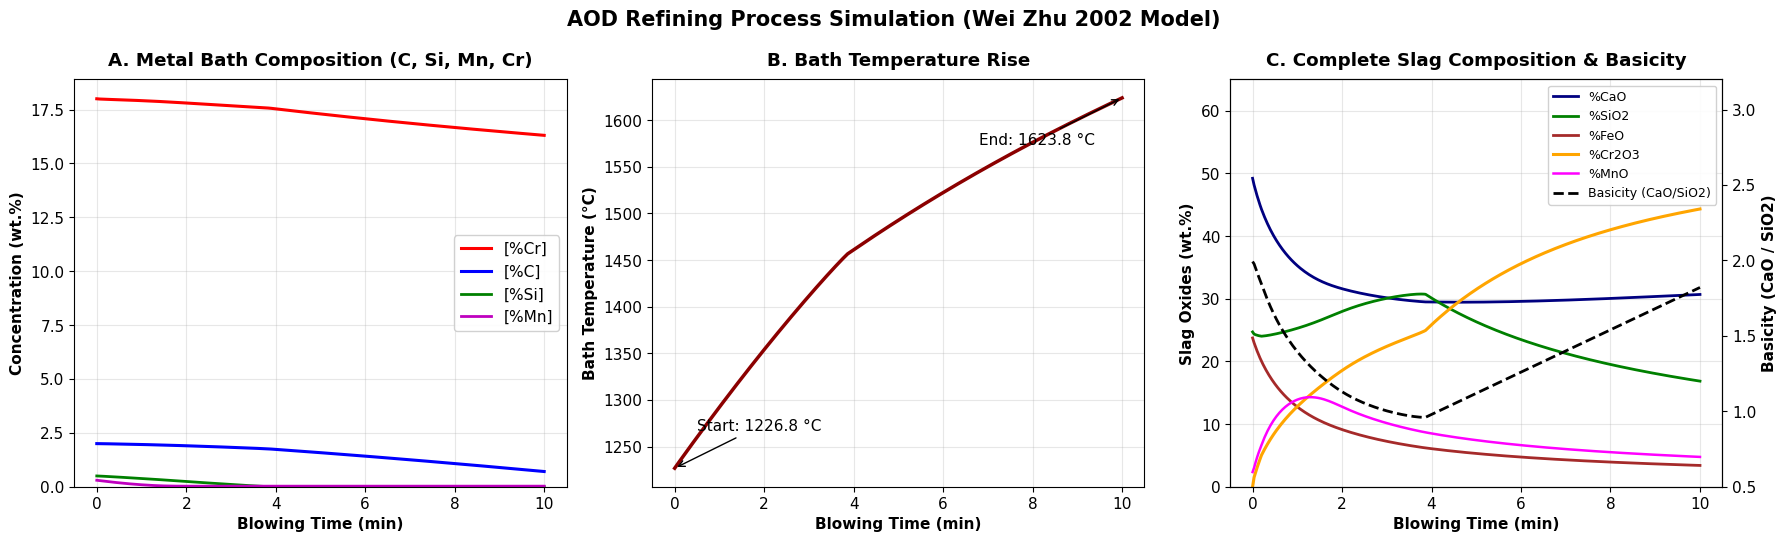

In [9]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Publication plotting style
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# =====================================================================
# 1. PHYSICAL CONSTANTS & MOLAR MASSES (kg/kmol)
# =====================================================================
R = 8.314  # Universal gas constant [J / (mol * K)]
V_M = 22.4  # Standard molar gas volume [m³ / kmol]

M = {
    'C': 12.011,
    'Si': 28.086,
    'Mn': 54.938,
    'Cr': 51.996,
    'Fe': 55.845,
    'O': 16.000,
    'O2': 31.998,
    'CO': 28.010,
    'CO2': 44.010,
    'FeO': 71.844,
    'SiO2': 60.084,
    'MnO': 70.937,
    'Cr2O3': 151.990,
    'CaO': 56.077,
    'MgO': 40.304,
    'Al2O3': 101.960,
}

# =====================================================================
# 2. WAGNER FIRST-ORDER INTERACTION PARAMETERS (e_i^j)
# =====================================================================
interaction_params = {
    'C': {
        'C': 0.14,
        'Cr': -0.024,
        'Mn': -0.012,
        'Si': 0.08,
        'O': -0.34,
        'Ni': 0.012,
        'Mo': -0.0083,
    },
    'Cr': {
        'C': -0.12,
        'Cr': -0.0003,
        'Mn': 0.0,
        'Si': -0.0043,
        'O': -0.14,
        'Ni': 0.0002,
        'Mo': 0.0018,
    },
    'Mn': {
        'C': -0.0538,
        'Cr': 0.0039,
        'Mn': 0.0,
        'Si': 0.0,
        'O': -0.083,
        'Ni': 0.0,
        'Mo': 0.0,
    },
    'Si': {
        'C': 0.24,
        'Cr': 0.015,
        'Mn': 0.002,
        'Si': 0.37,
        'O': 0.0,
        'Ni': 0.005,
        'Mo': 0.0,
    },
}

# =====================================================================
# 3. WEI ZHU (2002) THERMOCHEMICAL DATA & ENTHALPY EQUATIONS
# =====================================================================
# Equilibrium constant: log10(K) = A / T + B
K_COEFFS = {
    'C': (-3795.0, 4.164),
    'Si': (17770.0, -6.122),
    'Mn': (8695.0, -3.930),
    'Cr': (24025.0, -10.566),
}

# Specific heat capacities [J / (kg * K)] (Page 7 of Wei Zhu 2002)
CP = {
    'metal': 815.9,  # c_p,m (Liquid steel)
    'slag': 1196.6,  # c_p,s (Liquid slag)
    'O2': 918.4,  # c_p,O2
    'Ar': 523.8,  # c_p,Ar
    'CO': 1044.7,  # c_p,CO
    'CaO': 920.5,  # c_p,CaO (Lime)
    'scrap': 711.3,  # c_p,scrap
}

# Gas densities at standard conditions [kg / m³]
RHO = {'O2': 1.4277, 'Ar': 1.7821, 'metal': 7370.0, 'slag': 3100.0}

T_IN = 298.15  # Incoming gas & lime temperature [K] (~25 °C)


# Dynamic heats of reaction [J / kg of oxidized solute] (Wei Zhu Eqs. [39]-[42])
def delta_H_C(T_g):
  """Heat of C oxidation: [C] + 1/2 O2 -> CO (Eq. [39])."""
  dH_kJ = 11852.0 - (
      2.367 * T_g + 1.708e-4 * (T_g**2) + 3.835e3 / max(T_g, 100.0)
  )
  return dH_kJ * 1000.0


def delta_H_Cr(T):
  """Heat of Cr oxidation: 2[Cr] + 3/2 O2 -> Cr2O3 (Eq. [40])."""
  dH_kJ = 11519.0 - (1.148 * T + 4.4e-5 * (T**2) + 1.5e4 / max(T, 100.0))
  return dH_kJ * 1000.0


def delta_H_Si(T):
  """Heat of Si oxidation: [Si] + O2 -> SiO2 (Eq. [41])."""
  dH_kJ = 30658.0 - (2.15 * T + 1.45e-4 * (T**2))
  return dH_kJ * 1000.0


def delta_H_Mn(T):
  """Heat of Mn oxidation: [Mn] + 1/2 O2 -> MnO (Eq. [42])."""
  dH_kJ = 7581.0 - (0.845 * T + 7.38e-5 * (T**2) + 6.69e4 / max(T, 100.0))
  return dH_kJ * 1000.0


# =====================================================================
# 4. INITIAL OPERATING CONDITIONS
# =====================================================================
W_HM = 158000.0  # Hot metal mass [kg]
T_bath_0 = 1500.0  # Initial bath temperature [K] (1226.85 °C)
metal_pct_0 = {'C': 2.0, 'Si': 0.5, 'Mn': 0.3, 'Cr': 18.0, 'Fe': 79.2}  # wt.%

N_slag_0 = 30.0  # Initial slag quantity [kmol]
T_slag_0 = 1800.0  # Initial slag temperature [K]
slag_mol_frac_0 = {
    'FeO': 0.20,
    'SiO2': 0.2488,
    'CaO': 0.5312,
    'MnO': 0.02,
    'Cr2O3': 0.0,
    'MgO': 0.0,
    'Al2O3': 0.0,
}

# Gas blowing conditions
Q_O2 = 6.871  # Oxygen flow rate [m³/s]
Q_Ar = Q_O2 / 3.0  # Argon flow rate [m³/s] (Stage 1 O2:Ar = 3:1)
eta = 0.95  # Unified oxygen utilization efficiency
P_total = 1.05  # Total vessel pressure [atm]

# Simulation Timing: EXACT 10-MINUTE SIMULATION
dt = 2.0  # Time step [s]
duration_min = 10.0  # Total duration [minutes]
duration_sec = duration_min * 60.0  # 600 seconds
num_steps = int(duration_sec / dt)  # Exactly 300 steps

# Additions per step
lime_step_kg = 10.0  # Lime added per step [kg] to sustain basicity


# =====================================================================
# 5. THERMODYNAMIC & KINETIC FUNCTIONS
# =====================================================================
def calculate_metal_activities(metal_comp):
  """Calculates Henrian activities a_i for dissolved C, Si, Mn, Cr."""
  f, a = {}, {}
  for elem in ['C', 'Si', 'Mn', 'Cr']:
    log_f = sum(
        interaction_params[elem].get(j, 0.0) * metal_comp.get(j, 0.0)
        for j in ['C', 'Si', 'Mn', 'Cr']
    )
    f[elem] = 10.0**log_f
    a[elem] = max(f[elem] * metal_comp[elem], 1e-12)
  return f, a


def calculate_slag_activities(T_slag, slag_mol_frac, slag_pct_Cr2O3=0.0):
  """Calculates slag activities matching Wei Zhu (2002) Eqs. [27b]-[30b]."""
  N_CaO = slag_mol_frac.get('CaO', 0.0)
  N_MgO = slag_mol_frac.get('MgO', 0.0)
  N_SiO2 = slag_mol_frac.get('SiO2', 0.0)
  N_FeO = slag_mol_frac.get('FeO', 0.0)
  N_MnO = slag_mol_frac.get('MnO', 0.0)
  N_AlO15 = slag_mol_frac.get('Al2O3', 0.0)
  N_CrO15 = slag_mol_frac.get('Cr2O3', 0.0)
  N_basic = N_CaO + N_MgO

  # Turkdogan regular solution model (Eqs. 27b-30b)
  lg_g_FeO = (
      (4130.0 / T_slag) * N_basic * (N_SiO2 + 0.25 * N_AlO15)
      + (1720.0 / T_slag) * N_MnO * (N_SiO2 + 0.45 * N_CrO15)
      + (1246.0 / T_slag) * N_AlO15 * N_SiO2
      + (42.0 / T_slag) * N_MnO * N_AlO15
      + (692.0 / T_slag) * N_CrO15 * N_SiO2
  )

  lg_g_SiO2 = (
      lg_g_FeO
      - (4130.0 / T_slag) * N_basic
      - (1720.0 / T_slag) * N_MnO
      - (1246.0 / T_slag) * N_AlO15
      - (692.0 / T_slag) * N_CrO15
  )

  lg_g_MnO = (
      lg_g_FeO
      - (1720.0 / T_slag) * (N_SiO2 + 0.45 * N_CrO15)
      - (42.0 / T_slag) * N_AlO15
  )

  lg_g_Cr2O3 = (
      lg_g_FeO
      - (1859.0 / T_slag) * N_basic
      - (774.0 / T_slag) * N_MnO
      - (692.0 / T_slag) * N_SiO2
  )

  gamma = {
      'FeO': 10.0**lg_g_FeO,
      'SiO2': 10.0**lg_g_SiO2,
      'MnO': 10.0**lg_g_MnO,
      'Cr2O3': 10.0**lg_g_Cr2O3,
  }

  eps = 1e-15
  a_FeO = max(gamma['FeO'] * N_FeO, eps)
  a_SiO2 = max(gamma['SiO2'] * N_SiO2, eps)
  a_MnO = max(gamma['MnO'] * N_MnO, eps)

  # Wei Zhu 5% saturation rule for Cr2O3
  if slag_pct_Cr2O3 >= 5.0:
    a_Cr2O3 = 1.0
  else:
    a_Cr2O3 = max(gamma['Cr2O3'] * N_CrO15, eps)

  return gamma, {
      'FeO': a_FeO,
      'SiO2': a_SiO2,
      'MnO': a_MnO,
      'Cr2O3': a_Cr2O3,
  }


def calculate_equilibrium_constants(T_bath):
  """Calculates standard Gibbs energy Delta G°_i = -2.303 * R * T_bath * log10(K)."""
  delta_G_std = {}
  for elem, (A, B) in K_COEFFS.items():
    log_K = (A / T_bath) + B
    delta_G_std[elem] = -2.302585 * R * T_bath * log_K
  return delta_G_std


def calculate_reaction_gibbs(T_bath, a_metal, a_slag, delta_G_std, P_CO):
  """Calculates actual Gibbs free energy G_i (J/mol)."""
  eps = 1e-15
  RT = R * T_bath

  Q = {
      'C': max(P_CO, eps) / (a_metal['C'] * a_slag['FeO']),
      'Si': a_slag['SiO2'] / (a_metal['Si'] * (a_slag['FeO'] ** 2)),
      'Mn': a_slag['MnO'] / (a_metal['Mn'] * a_slag['FeO']),
      'Cr': a_slag['Cr2O3'] / ((a_metal['Cr'] ** 2) * (a_slag['FeO'] ** 3)),
  }

  G = {elem: delta_G_std[elem] + RT * math.log(Q[elem]) for elem in Q}
  return Q, G


def calculate_oxygen_distribution(G, metal_comp):
  """Calculates X_i using driving force modulus, with cutoff if G >= 0 or element depleted."""
  w = {}
  w['C'] = abs(G['C']) if (G['C'] < 0 and metal_comp['C'] > 0.001) else 0.0
  w['Si'] = (
      (abs(G['Si']) / 2.0)
      if (G['Si'] < 0 and metal_comp['Si'] > 0.001)
      else 0.0
  )
  w['Mn'] = abs(G['Mn']) if (G['Mn'] < 0 and metal_comp['Mn'] > 0.001) else 0.0
  w['Cr'] = (
      (abs(G['Cr']) / 3.0)
      if (G['Cr'] < 0 and metal_comp['Cr'] > 0.001)
      else 0.0
  )

  total_w = sum(w.values())
  if total_w <= 0.0:
    return {'C': 0.25, 'Si': 0.25, 'Mn': 0.25, 'Cr': 0.25}

  return {elem: w[elem] / total_w for elem in w}


def calculate_oxidation_rates(Q_O2, X, metal_kg, dt, eta=0.95):
  """Calculates oxidation rates with physical depletion clamps."""
  W_m = sum(metal_kg.values())
  n_dot_O2 = Q_O2 / V_M

  stoich = {'C': 2.0, 'Si': 1.0, 'Mn': 2.0, 'Cr': 4.0 / 3.0}
  rate_pct_s, delta_pct, delta_kg = {}, {}, {}

  for elem in ['C', 'Si', 'Mn', 'Cr']:
    rate = (
        stoich[elem]
        * eta
        * n_dot_O2
        * X[elem]
        * (100.0 * M[elem] / W_m)
        if metal_kg[elem] > 0.0
        else 0.0
    )
    d_pct = rate * dt
    d_kg = (d_pct / 100.0) * W_m

    # Physical clamp: cannot remove more than currently present in bath
    d_kg = min(d_kg, max(metal_kg[elem], 0.0))
    d_pct = (d_kg / W_m) * 100.0

    rate_pct_s[elem] = rate
    delta_pct[elem] = d_pct
    delta_kg[elem] = d_kg

  return rate_pct_s, delta_pct, delta_kg


def calculate_dynamic_P_CO(delta_kg_C, Q_O2, Q_Ar, dt, eta, P_total=1.05):
  """Calculates dynamic P_CO from actual carbon burned and Argon blown (Wei Zhu Eq. 16)."""
  n_CO = delta_kg_C / M['C']
  n_Ar = (Q_Ar * dt) / V_M
  n_O_unreact = (Q_O2 * (1.0 - eta) * dt) / V_M

  total_gas = n_CO + n_Ar + n_O_unreact
  if total_gas <= 0.0:
    return 0.75

  P_CO = (n_CO / total_gas) * P_total
  return max(min(P_CO, P_total), 0.05)


def calculate_bath_temperature_rise(
    T_curr,
    metal_kg_curr,
    slag_kg_curr,
    delta_kg,
    dt,
    Q_O2=6.871,
    Q_Ar=2.290,
    eta=0.95,
    lime_add_kg=0.0,
    q_loss_W=0.0,
):
  """Calculates new bath temperature T_new using Wei Zhu (2002) Eq. [22]."""
  W_m = sum(metal_kg_curr.values())
  W_s = sum(slag_kg_curr.values())

  # 1. Elemental oxidation rates r_i in [wt.% / s]
  r = {el: (delta_kg.get(el, 0.0) / W_m) * (100.0 / dt) for el in delta_kg}

  # 2. Chemical reaction heat generated (Eqs. 39 - 42)
  q_rxn = (
      delta_H_C(T_curr) * r.get('C', 0.0)
      + delta_H_Cr(T_curr) * r.get('Cr', 0.0)
      + delta_H_Si(T_curr) * r.get('Si', 0.0)
      + delta_H_Mn(T_curr) * r.get('Mn', 0.0)
  )

  # 3. Slag formation sensible heat absorbed (Term 1 in Eq. 22)
  stoich_slag = (
      (M['Cr2O3'] / (2.0 * M['Cr'])) * r.get('Cr', 0.0)
      + (M['MnO'] / M['Mn']) * r.get('Mn', 0.0)
      + (M['SiO2'] / M['Si']) * r.get('Si', 0.0)
  )
  term_slag_form = -CP['slag'] * T_curr * stoich_slag

  # 4. Solute loss sensible heat from metal bath (Term 2 in Eq. 22)
  term_metal_loss = (
      CP['metal']
      * T_curr
      * (r.get('C', 0.0) + r.get('Cr', 0.0) + r.get('Mn', 0.0) + r.get('Si', 0.0))
  )

  # 5. Off-gas (CO) sensible heat carried away (Term 4 in Eq. 22)
  term_CO_gas = -CP['CO'] * T_curr * (M['CO'] / M['C']) * r.get('C', 0.0)

  # 6. Cold gas heating & external heat losses (Term 3 in Eq. 22)
  m_dot_O2_unreact = Q_O2 * (1.0 - eta) * RHO['O2']
  m_dot_Ar = Q_Ar * RHO['Ar']
  q_gas = (m_dot_O2_unreact * CP['O2'] + m_dot_Ar * CP['Ar']) * (T_curr - T_IN)

  lime_rate_kg_s = lime_add_kg / dt
  q_lime = lime_rate_kg_s * CP['CaO'] * (T_curr - T_IN)

  term_losses = (100.0 / W_m) * (q_gas + q_loss_W + q_lime)

  # 7. Numerator and Denominator of Eq. [22]
  numerator = (
      q_rxn + term_slag_form + term_metal_loss + term_CO_gas - term_losses
  )
  denominator = 100.0 * CP['metal'] + 100.0 * CP['slag'] * (W_s / W_m)

  # Rate of temperature rise [K / s]
  dT_dt = numerator / denominator
  delta_T = dT_dt * dt
  T_new = T_curr + delta_T

  # 8. Mass balances for metal and slag
  metal_kg_new = {
      el: max(metal_kg_curr[el] - delta_kg.get(el, 0.0), 0.0)
      for el in metal_kg_curr
  }

  slag_kg_new = dict(slag_kg_curr)
  slag_kg_new['SiO2'] = (
      slag_kg_new.get('SiO2', 0.0) + delta_kg['Si'] * (M['SiO2'] / M['Si'])
  )
  slag_kg_new['MnO'] = (
      slag_kg_new.get('MnO', 0.0) + delta_kg['Mn'] * (M['MnO'] / M['Mn'])
  )
  slag_kg_new['Cr2O3'] = (
      slag_kg_new.get('Cr2O3', 0.0)
      + delta_kg['Cr'] * (M['Cr2O3'] / (2.0 * M['Cr']))
  )
  slag_kg_new['CaO'] = slag_kg_new.get('CaO', 0.0) + lime_add_kg

  return T_new, delta_T, dT_dt, metal_kg_new, slag_kg_new


# =====================================================================
# 6. SIMULATION EXECUTION LOOP
# =====================================================================
# Initialize State
T_current = T_bath_0
metal_kg = {el: (pct / 100.0) * W_HM for el, pct in metal_pct_0.items()}
slag_kg = {
    ox: (N_slag_0 * frac) * M[ox]
    for ox, frac in slag_mol_frac_0.items()
    if frac > 0
}
P_CO_current = 0.75

history = []

# Step 0: Initial Condition Baseline
W_m0 = sum(metal_kg.values())
W_s0 = sum(slag_kg.values())
history.append({
    'step': 0,
    'time_min': 0.0,
    'time_sec': 0.0,
    'T_bath_C': T_current - 273.15,
    'T_bath_K': T_current,
    'C_pct': metal_pct_0['C'],
    'Si_pct': metal_pct_0['Si'],
    'Mn_pct': metal_pct_0['Mn'],
    'Cr_pct': metal_pct_0['Cr'],
    'Fe_pct': metal_pct_0['Fe'],
    'W_metal_kg': W_m0,
    'W_slag_kg': W_s0,
    'Cr2O3_pct': (slag_kg.get('Cr2O3', 0.0) / W_s0) * 100.0,
    'SiO2_pct': (slag_kg.get('SiO2', 0.0) / W_s0) * 100.0,
    'CaO_pct': (slag_kg.get('CaO', 0.0) / W_s0) * 100.0,
    'FeO_pct': (slag_kg.get('FeO', 0.0) / W_s0) * 100.0,
    'MnO_pct': (slag_kg.get('MnO', 0.0) / W_s0) * 100.0,
    'basicity': slag_kg.get('CaO', 0.0) / max(slag_kg.get('SiO2', 1e-4), 1e-4),
    'X_C': 0.0,
    'X_Si': 0.0,
    'X_Mn': 0.0,
    'X_Cr': 0.0,
    'P_CO_atm': P_CO_current,
    'dT_dt_K_min': 0.0,
})

print(
    f'Executing AOD Simulation: {duration_min:.1f} min ({num_steps} steps, dt ='
    f' {dt} s)...'
)

for step in range(1, num_steps + 1):
  time_sec = step * dt
  time_min = time_sec / 60.0

  # 1. Current State Calculations
  W_m = sum(metal_kg.values())
  W_s = sum(slag_kg.values())

  curr_metal_pct = {el: (kg / W_m) * 100.0 for el, kg in metal_kg.items()}
  curr_slag_pct = {ox: (kg / W_s) * 100.0 for ox, kg in slag_kg.items()}

  slag_moles = {ox: kg / M[ox] for ox, kg in slag_kg.items() if ox in M}
  tot_n = sum(slag_moles.values())
  curr_slag_mol_frac = {ox: n / tot_n for ox, n in slag_moles.items()}

  # 2. Thermodynamic Activities & Driving Forces
  _, a_metal = calculate_metal_activities(curr_metal_pct)
  _, a_slag = calculate_slag_activities(
      T_current, curr_slag_mol_frac, curr_slag_pct.get('Cr2O3', 0.0)
  )
  dG_std = calculate_equilibrium_constants(T_current)
  _, G = calculate_reaction_gibbs(
      T_current, a_metal, a_slag, dG_std, P_CO_current
  )
  X = calculate_oxygen_distribution(G, curr_metal_pct)

  # 3. Oxidation Kinetics
  rate_s, d_pct, d_kg = calculate_oxidation_rates(Q_O2, X, metal_kg, dt, eta)

  # 4. Dynamic P_CO Calculation
  P_CO_next = calculate_dynamic_P_CO(d_kg['C'], Q_O2, Q_Ar, dt, eta, P_total)

  # 5. Coupled Temperature Rise (Wei Zhu Eq. 22)
  T_new, delta_T, dT_dt, metal_kg_new, slag_kg_new = (
      calculate_bath_temperature_rise(
          T_curr=T_current,
          metal_kg_curr=metal_kg,
          slag_kg_curr=slag_kg,
          delta_kg=d_kg,
          dt=dt,
          Q_O2=Q_O2,
          Q_Ar=Q_Ar,
          eta=eta,
          lime_add_kg=lime_step_kg,
          q_loss_W=0.0,
      )
  )

  # 6. State Handover (Accurately update before recording current step)
  metal_kg = metal_kg_new
  slag_kg = slag_kg_new
  T_current = T_new
  P_CO_current = P_CO_next

  W_m_updated = sum(metal_kg.values())
  W_s_updated = sum(slag_kg.values())
  new_metal_pct = {
      el: (kg / W_m_updated) * 100.0 for el, kg in metal_kg.items()
  }
  new_slag_pct = {ox: (kg / W_s_updated) * 100.0 for ox, kg in slag_kg.items()}

  # 7. Record Telemetry
  history.append({
      'step': step,
      'time_min': time_min,
      'time_sec': time_sec,
      'T_bath_C': T_current - 273.15,
      'T_bath_K': T_current,
      'C_pct': new_metal_pct['C'],
      'Si_pct': new_metal_pct['Si'],
      'Mn_pct': new_metal_pct['Mn'],
      'Cr_pct': new_metal_pct['Cr'],
      'Fe_pct': new_metal_pct['Fe'],
      'W_metal_kg': W_m_updated,
      'W_slag_kg': W_s_updated,
      'Cr2O3_pct': new_slag_pct.get('Cr2O3', 0.0),
      'SiO2_pct': new_slag_pct.get('SiO2', 0.0),
      'CaO_pct': new_slag_pct.get('CaO', 0.0),
      'FeO_pct': new_slag_pct.get('FeO', 0.0),
      'MnO_pct': new_slag_pct.get('MnO', 0.0),
      'basicity': new_slag_pct.get('CaO', 0.0)
      / max(new_slag_pct.get('SiO2', 1e-4), 1e-4),
      'X_C': X['C'],
      'X_Si': X['Si'],
      'X_Mn': X['Mn'],
      'X_Cr': X['Cr'],
      'P_CO_atm': P_CO_current,
      'dT_dt_K_min': dT_dt * 60.0,
  })

df_sim = pd.DataFrame(history)
print('Simulation Finished Successfully!\n')

# =====================================================================
# 7. MILESTONE PROGRESSION TABLE
# =====================================================================
# Milestones at exact times: 0 min, 1 min, 2 min, 5 min, 10 min
milestone_steps = [0, 30, 60, 150, 300]
print('=' * 95)
print('AOD REFINING SIMULATION - MILESTONE PROGRESSION')
print('=' * 95)
print(
    df_sim.iloc[milestone_steps][[
        'time_min',
        'T_bath_C',
        'C_pct',
        'Si_pct',
        'Mn_pct',
        'Cr_pct',
        'Cr2O3_pct',
        'basicity',
        'P_CO_atm',
    ]].to_string(index=False)
)
print('=' * 95)

# =====================================================================
# 8. THREE-PANEL VISUALIZATION PLOT
# =====================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
t = df_sim['time_min']

# ---------------------------------------------------------------------
# GRAPH 1: METAL BATH COMPOSITION
# ---------------------------------------------------------------------
axes[0].plot(t, df_sim['Cr_pct'], 'r-', lw=2.2, label='[%Cr]')
axes[0].plot(t, df_sim['C_pct'], 'b-', lw=2.2, label='[%C]')
axes[0].plot(t, df_sim['Si_pct'], 'g-', lw=2.0, label='[%Si]')
axes[0].plot(t, df_sim['Mn_pct'], 'm-', lw=2.0, label='[%Mn]')

axes[0].set_xlabel('Blowing Time (min)', fontweight='bold')
axes[0].set_ylabel('Concentration (wt.%)', fontweight='bold')
axes[0].set_title(
    'A. Metal Bath Composition (C, Si, Mn, Cr)', fontweight='bold', pad=10
)
axes[0].legend(loc='center right', framealpha=0.9)
axes[0].set_ylim(bottom=0)

# ---------------------------------------------------------------------
# GRAPH 2: BATH TEMPERATURE RISE
# ---------------------------------------------------------------------
axes[1].plot(t, df_sim['T_bath_C'], color='darkred', lw=2.5)
axes[1].set_xlabel('Blowing Time (min)', fontweight='bold')
axes[1].set_ylabel('Bath Temperature (°C)', fontweight='bold')
axes[1].set_title('B. Bath Temperature Rise', fontweight='bold', pad=10)

t_start = df_sim['T_bath_C'].iloc[0]
t_end = df_sim['T_bath_C'].iloc[-1]
axes[1].annotate(
    f'Start: {t_start:.1f} °C',
    xy=(0, t_start),
    xytext=(0.5, t_start + 40),
    arrowprops=dict(arrowstyle='->', color='black'),
)
axes[1].annotate(
    f'End: {t_end:.1f} °C',
    xy=(t.iloc[-1], t_end),
    xytext=(t.iloc[-1] - 3.2, t_end - 50),
    arrowprops=dict(arrowstyle='->', color='black'),
)

# ---------------------------------------------------------------------
# GRAPH 3: COMPLETE SLAG COMPOSITION (ALL OXIDES) + BASICITY
# ---------------------------------------------------------------------
axes[2].plot(t, df_sim['CaO_pct'], color='navy', lw=2.0, label='%CaO')
axes[2].plot(t, df_sim['SiO2_pct'], color='green', lw=2.0, label='%SiO2')
axes[2].plot(t, df_sim['FeO_pct'], color='brown', lw=2.0, label='%FeO')
axes[2].plot(t, df_sim['Cr2O3_pct'], color='orange', lw=2.2, label='%Cr2O3')
axes[2].plot(t, df_sim['MnO_pct'], color='magenta', lw=1.8, label='%MnO')

axes[2].set_xlabel('Blowing Time (min)', fontweight='bold')
axes[2].set_ylabel('Slag Oxides (wt.%)', fontweight='bold')
axes[2].set_title(
    'C. Complete Slag Composition & Basicity', fontweight='bold', pad=10
)
axes[2].set_ylim(0, 65)

# Secondary Y-axis for Basicity
ax_bas = axes[2].twinx()
ax_bas.plot(
    t,
    df_sim['basicity'],
    color='black',
    ls='--',
    lw=2.0,
    label='Basicity (CaO/SiO2)',
)
ax_bas.set_ylabel('Basicity (CaO / SiO2)', fontweight='bold', color='black')
ax_bas.set_ylim(0.5, 3.2)
ax_bas.grid(False)

# Combine legends from both axes
lines_1, labels_1 = axes[2].get_legend_handles_labels()
lines_2, labels_2 = ax_bas.get_legend_handles_labels()
axes[2].legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc='upper right',
    fontsize=9,
    framealpha=0.9,
)

# Clean layout with space reserved for suptitle
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.suptitle(
    'AOD Refining Process Simulation (Wei Zhu 2002 Model)',
    fontsize=15,
    fontweight='bold',
)
plt.show()

Executing Sequential AOD Simulation (Pure O2, t = 2 to 600 s, dt = 2.0 s)...
Simulation Finished Successfully!

AOD SIMULATION MILESTONES (Pure O2 Blowing)
 time_min    T_bath_C    C_pct   Si_pct   Mn_pct    Cr_pct  Cr2O3_pct  basicity  P_CO_atm
      0.0 1426.850000 2.000000 0.500000 0.300000 18.000000   0.000000  1.992662  0.900000
      1.0 1486.339959 1.943240 0.381094 0.132559 17.924809  12.002488  1.392579  0.962615
      2.0 1541.310708 1.864936 0.247922 0.082860 17.842313  16.902856  1.141499  0.977168
      5.0 1659.079931 1.465704 0.000577 0.082490 17.538119  26.088274  1.120307  1.014009
     10.0 1750.500367 0.412942 0.000588 0.084104 17.006652  35.720719  1.822358  1.016332


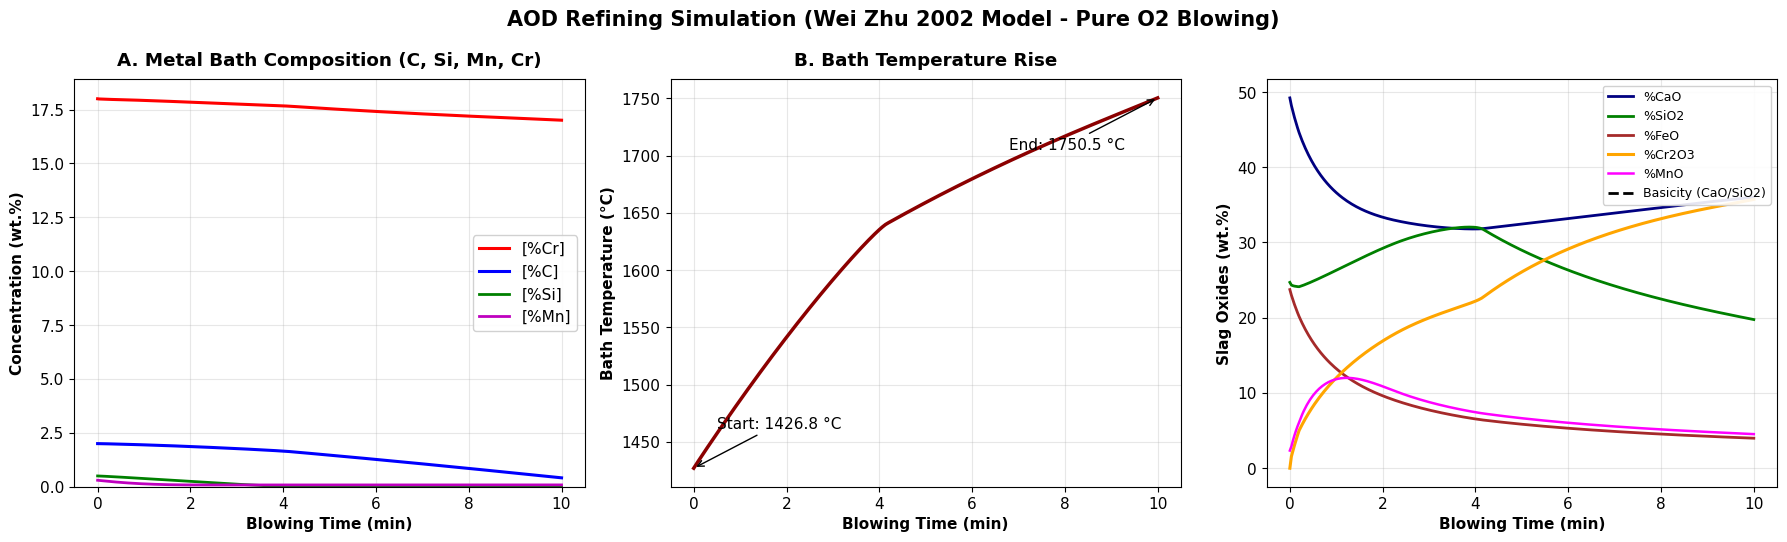

In [ ]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Publication plotting style
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# =====================================================================
# 1. PHYSICAL CONSTANTS & MOLAR MASSES (kg/kmol)
# =====================================================================
R = 8.314  # Universal gas constant [J / (mol * K)]
V_M = 22.4  # Standard molar gas volume [m³ / kmol]

M = {
    'C': 12.011,
    'Si': 28.086,
    'Mn': 54.938,
    'Cr': 51.996,
    'Fe': 55.845,
    'O': 16.000,
    'O2': 31.998,
    'CO': 28.010,
    'CO2': 44.010,
    'FeO': 71.844,
    'SiO2': 60.084,
    'MnO': 70.937,
    'Cr2O3': 151.990,
    'CaO': 56.077,
    'MgO': 40.304,
    'Al2O3': 101.960,
}

# =====================================================================
# 2. WAGNER FIRST-ORDER INTERACTION PARAMETERS (e_i^j)
# =====================================================================
interaction_params = {
    'C': {
        'C': 0.14,
        'Cr': -0.024,
        'Mn': -0.012,
        'Si': 0.08,
        'O': -0.34,
        'Ni': 0.012,
        'Mo': -0.0083,
    },
    'Cr': {
        'C': -0.12,
        'Cr': -0.0003,
        'Mn': 0.0,
        'Si': -0.0043,
        'O': -0.14,
        'Ni': 0.0002,
        'Mo': 0.0018,
    },
    'Mn': {
        'C': -0.0538,
        'Cr': 0.0039,
        'Mn': 0.0,
        'Si': 0.0,
        'O': -0.083,
        'Ni': 0.0,
        'Mo': 0.0,
    },
    'Si': {
        'C': 0.24,
        'Cr': 0.015,
        'Mn': 0.002,
        'Si': 0.37,
        'O': 0.0,
        'Ni': 0.005,
        'Mo': 0.0,
    },
}

# Equilibrium constants: log10(K) = A / T + B
K_COEFFS = {
    'C': (-3795.0, 4.164),
    'Si': (17770.0, -6.122),
    'Mn': (8695.0, -3.930),
    'Cr': (24025.0, -10.566),
}

# =====================================================================
# 3. WEI ZHU (2002) THERMOCHEMICAL DATA & ENTHALPIES
# =====================================================================
CP = {
    'metal': 815.9,  # c_p,m (Liquid steel) [J / (kg * K)]
    'slag': 1196.6,  # c_p,s (Liquid slag) [J / (kg * K)]
    'O2': 918.4,  # c_p,O2 (Oxygen) [J / (kg * K)]
    'CO': 1044.7,  # c_p,CO (Carbon monoxide) [J / (kg * K)]
    'CaO': 920.5,  # c_p,CaO (Lime) [J / (kg * K)]
}

RHO = {'O2': 1.4277, 'metal': 7370.0, 'slag': 3100.0}

T_IN = 298.15  # Incoming gas & lime temperature [K] (~25 °C)


# Temperature-dependent heats of reaction [J / kg of oxidized solute] (Eqs. 39 - 42)
def delta_H_C(T):
  dH_kJ = 11852.0 - (2.367 * T + 1.708e-4 * (T**2) + 3.835e3 / max(T, 100.0))
  return dH_kJ * 1000.00


def delta_H_Cr(T):
  dH_kJ = 11519.0 - (1.148 * T + 4.4e-5 * (T**2) + 1.5e4 / max(T, 100.0))
  return dH_kJ * 1000.0


def delta_H_Si(T):
  dH_kJ = 30658.0 - (2.15 * T + 1.45e-4 * (T**2))
  return dH_kJ * 1000.0


def delta_H_Mn(T):
  dH_kJ = 7581.0 - (0.845 * T + 7.38e-5 * (T**2) + 6.69e4 / max(T, 100.0))
  return dH_kJ * 1000.0


# =====================================================================
# 4. INITIAL OPERATING CONDITIONS
# =====================================================================
W_HM = 158000.0  # Hot metal mass [kg]
T_bath_0 = 1700.0  # Initial bath temperature [K] (1226.85 °C)
metal_pct_0 = {'C': 2.0, 'Si': 0.5, 'Mn': 0.3, 'Cr': 18.0, 'Fe': 79.2}  # wt.%

N_slag_0 = 30.0  # Initial slag quantity [kmol]
T_slag_0 = 1800.0  # Slag temperature [K]
slag_mol_frac_0 = {
    'FeO': 0.20,
    'SiO2': 0.2488,
    'CaO': 0.5312,
    'MnO': 0.02,
    'Cr2O3': 0.0,
    'MgO': 0.0,
    'Al2O3': 0.0,
}

# Gas Blowing: PURE OXYGEN ONLY (NO ARGON)
Q_O2 = 6.871  # Oxygen flow rate [m³/s]
Q_Ar = 0.0  # NO Argon blowing for now
eta = 0.95  # Unified oxygen efficiency
P_total = 1.05  # Total vessel pressure [atm]

# Additions per step
lime_step_kg = 10.0  # Lime added per 2-second step [kg]

# Simulation Timing
dt = 2.0  # Step size [s]
t_start = 2  # Start time [s]
t_end = 600  # End time [s] (10 min)


# =====================================================================
# 5. CORE THERMODYNAMIC & KINETIC FUNCTIONS
# =====================================================================
def calculate_metal_activities(metal_comp):
  """Calculates Henrian activities a_i for dissolved solutes."""
  f, a = {}, {}
  for elem in ['C', 'Si', 'Mn', 'Cr']:
    log_f = sum(
        interaction_params[elem].get(j, 0.0) * metal_comp.get(j, 0.0)
        for j in ['C', 'Si', 'Mn', 'Cr']
    )
    f[elem] = 10.0**log_f
    a[elem] = max(f[elem] * metal_comp[elem], 1e-12)
  return f, a


def calculate_slag_activities(T_slag, slag_mol_frac, slag_pct_Cr2O3=0.0):
  """Calculates slag activities (Wei Zhu Eqs. [27b]-[30b])."""
  N_CaO = slag_mol_frac.get('CaO', 0.0)
  N_MgO = slag_mol_frac.get('MgO', 0.0)
  N_SiO2 = slag_mol_frac.get('SiO2', 0.0)
  N_FeO = slag_mol_frac.get('FeO', 0.0)
  N_MnO = slag_mol_frac.get('MnO', 0.0)
  N_AlO15 = slag_mol_frac.get('Al2O3', 0.0)
  N_CrO15 = slag_mol_frac.get('Cr2O3', 0.0)
  N_basic = N_CaO + N_MgO

  lg_g_FeO = (
      (4130.0 / T_slag) * N_basic * (N_SiO2 + 0.25 * N_AlO15)
      + (1720.0 / T_slag) * N_MnO * (N_SiO2 + 0.45 * N_CrO15)
      + (1246.0 / T_slag) * N_AlO15 * N_SiO2
      + (42.0 / T_slag) * N_MnO * N_AlO15
      + (692.0 / T_slag) * N_CrO15 * N_SiO2
  )

  lg_g_SiO2 = (
      lg_g_FeO
      - (4130.0 / T_slag) * N_basic
      - (1720.0 / T_slag) * N_MnO
      - (1246.0 / T_slag) * N_AlO15
      - (692.0 / T_slag) * N_CrO15
  )

  lg_g_MnO = (
      lg_g_FeO
      - (1720.0 / T_slag) * (N_SiO2 + 0.45 * N_CrO15)
      - (42.0 / T_slag) * N_AlO15
  )

  lg_g_Cr2O3 = (
      lg_g_FeO
      - (1859.0 / T_slag) * N_basic
      - (774.0 / T_slag) * N_MnO
      - (692.0 / T_slag) * N_SiO2
  )

  gamma = {
      'FeO': 10.0**lg_g_FeO,
      'SiO2': 10.0**lg_g_SiO2,
      'MnO': 10.0**lg_g_MnO,
      'Cr2O3': 10.0**lg_g_Cr2O3,
  }

  eps = 1e-15
  a_FeO = max(gamma['FeO'] * N_FeO, eps)
  a_SiO2 = max(gamma['SiO2'] * N_SiO2, eps)
  a_MnO = max(gamma['MnO'] * N_MnO, eps)

  # 5% Cr2O3 saturation rule
  if slag_pct_Cr2O3 >= 5.0:
    a_Cr2O3 = 1.0
  else:
    a_Cr2O3 = max(gamma['Cr2O3'] * N_CrO15, eps)

  return gamma, {
      'FeO': a_FeO,
      'SiO2': a_SiO2,
      'MnO': a_MnO,
      'Cr2O3': a_Cr2O3,
  }


def calculate_equilibrium_constants(T_bath):
  """Calculates standard Gibbs energy Delta G°_i = -2.303 * R * T_bath * log10(K)."""
  delta_G_std = {}
  for elem, (A, B) in K_COEFFS.items():
    log_K = (A / T_bath) + B
    delta_G_std[elem] = -2.302585 * R * T_bath * log_K
  return delta_G_std


def calculate_reaction_gibbs(T_bath, a_metal, a_slag, delta_G_std, P_CO):
  """Calculates reaction quotients Q_i and instantaneous Gibbs free energies G_i."""
  eps = 1e-15
  RT = R * T_bath

  Q = {
      'C': max(P_CO, eps) / (a_metal['C'] * a_slag['FeO']),
      'Si': a_slag['SiO2'] / (a_metal['Si'] * (a_slag['FeO'] ** 2)),
      'Mn': a_slag['MnO'] / (a_metal['Mn'] * a_slag['FeO']),
      'Cr': a_slag['Cr2O3'] / ((a_metal['Cr'] ** 2) * (a_slag['FeO'] ** 3)),
  }

  G = {elem: delta_G_std[elem] + RT * math.log(Q[elem]) for elem in Q}
  return Q, G


def calculate_oxygen_distribution(G, metal_comp):
  """Calculates oxygen distribution ratios X_i using driving force modulus."""
  w = {}
  w['C'] = abs(G['C']) if (G['C'] < 0 and metal_comp['C'] > 0.001) else 0.0
  w['Si'] = (
      (abs(G['Si']) / 2.0)
      if (G['Si'] < 0 and metal_comp['Si'] > 0.001)
      else 0.0
  )
  w['Mn'] = abs(G['Mn']) if (G['Mn'] < 0 and metal_comp['Mn'] > 0.001) else 0.0
  w['Cr'] = (
      (abs(G['Cr']) / 3.0)
      if (G['Cr'] < 0 and metal_comp['Cr'] > 0.001)
      else 0.0
  )

  total_w = sum(w.values())
  if total_w <= 0.0:
    return {'C': 0.25, 'Si': 0.25, 'Mn': 0.25, 'Cr': 0.25}

  return {elem: w[elem] / total_w for elem in w}


def calculate_oxidation_rates(Q_O2, X, metal_kg, dt, eta=0.95):
  """Calculates oxidation rates with physical depletion clamps."""
  W_m = sum(metal_kg.values())
  n_dot_O2 = Q_O2 / V_M

  stoich = {'C': 2.0, 'Si': 1.0, 'Mn': 2.0, 'Cr': 4.0 / 3.0}
  rate_pct_s, delta_pct, delta_kg = {}, {}, {}

  for elem in ['C', 'Si', 'Mn', 'Cr']:
    rate = (
        stoich[elem]
        * eta
        * n_dot_O2
        * X[elem]
        * (100.0 * M[elem] / W_m)
        if metal_kg[elem] > 0.0
        else 0.0
    )
    d_pct = rate * dt
    d_kg = (d_pct / 100.0) * W_m

    # Physical clamp: cannot burn more than bath contains
    d_kg = min(d_kg, max(metal_kg[elem], 0.0))
    d_pct = (d_kg / W_m) * 100.0

    rate_pct_s[elem] = rate
    delta_pct[elem] = d_pct
    delta_kg[elem] = d_kg

  return rate_pct_s, delta_pct, delta_kg


def calculate_dynamic_P_CO(delta_kg_C, Q_O2, dt, eta, P_total=1.05):
  """Calculates dynamic P_CO under Pure Oxygen blowing (Wei Zhu Eq. 16, Q_Ar = 0)."""
  n_CO = delta_kg_C / M['C']
  n_O_unreact = (Q_O2 * (1.0 - eta) * dt) / V_M

  total_gas = n_CO + n_O_unreact
  if total_gas <= 0.0:
    return 0.90  # Default initial P_CO

  P_CO = (n_CO / total_gas) * P_total
  return max(min(P_CO, P_total), 0.05)


def calculate_bath_temperature_rise(
    T_curr,
    metal_kg_curr,
    slag_kg_curr,
    delta_kg,
    dt,
    Q_O2=6.871,
    eta=0.95,
    lime_add_kg=0.0,
):
  """Calculates bath temperature rising rate dT/dt and T_new using Wei Zhu Eq. [22]."""
  W_m = sum(metal_kg_curr.values())
  W_s = sum(slag_kg_curr.values())

  # 1. Elemental oxidation rates r_i in [wt.% / s]
  r = {el: (delta_kg.get(el, 0.0) / W_m) * (100.0 / dt) for el in delta_kg}

  # 2. Chemical reaction heat generated (Eqs. 39 - 42)
  q_rxn = (
      delta_H_C(T_curr) * r.get('C', 0.0)
      + delta_H_Cr(T_curr) * r.get('Cr', 0.0)
      + delta_H_Si(T_curr) * r.get('Si', 0.0)
      + delta_H_Mn(T_curr) * r.get('Mn', 0.0)
  )

  # 3. Slag formation sensible heat absorbed (Term 1 in Eq. 22)
  stoich_slag = (
      (M['Cr2O3'] / (2.0 * M['Cr'])) * r.get('Cr', 0.0)
      + (M['MnO'] / M['Mn']) * r.get('Mn', 0.0)
      + (M['SiO2'] / M['Si']) * r.get('Si', 0.0)
  )
  term_slag_form = -CP['slag'] * T_curr * stoich_slag

  # 4. Solute loss sensible heat from metal bath (Term 2 in Eq. 22)
  term_metal_loss = (
      CP['metal']
      * T_curr
      * (r.get('C', 0.0) + r.get('Cr', 0.0) + r.get('Mn', 0.0) + r.get('Si', 0.0))
  )

  # 5. Off-gas (CO) sensible heat carried away (Term 4 in Eq. 22)
  term_CO_gas = -CP['CO'] * T_curr * (M['CO'] / M['C']) * r.get('C', 0.0)

  # 6. Cold gas heating & lime heat absorption (Term 3 in Eq. 22 with Q_Ar = 0)
  m_dot_O2_unreact = Q_O2 * (1.0 - eta) * RHO['O2']
  q_gas = m_dot_O2_unreact * CP['O2'] * (T_curr - T_IN)

  lime_rate_kg_s = lime_add_kg / dt
  q_lime = lime_rate_kg_s * CP['CaO'] * (T_curr - T_IN)

  term_losses = (100.0 / W_m) * (q_gas + q_lime)

  # 7. Numerator and Denominator of Eq. [22]
  numerator = (
      q_rxn + term_slag_form + term_metal_loss + term_CO_gas - term_losses
  )
  denominator = 100.0 * CP['metal'] + 100.0 * CP['slag'] * (W_s / W_m)

  dT_dt = numerator / denominator
  delta_T = dT_dt * dt
  T_new = T_curr + delta_T

  # 8. Mass balances for metal and slag
  metal_kg_new = {
      el: max(metal_kg_curr[el] - delta_kg.get(el, 0.0), 0.0)
      for el in metal_kg_curr
  }

  slag_kg_new = dict(slag_kg_curr)
  slag_kg_new['SiO2'] = (
      slag_kg_new.get('SiO2', 0.0) + delta_kg['Si'] * (M['SiO2'] / M['Si'])
  )
  slag_kg_new['MnO'] = (
      slag_kg_new.get('MnO', 0.0) + delta_kg['Mn'] * (M['MnO'] / M['Mn'])
  )
  slag_kg_new['Cr2O3'] = (
      slag_kg_new.get('Cr2O3', 0.0)
      + delta_kg['Cr'] * (M['Cr2O3'] / (2.0 * M['Cr']))
  )
  slag_kg_new['CaO'] = slag_kg_new.get('CaO', 0.0) + lime_add_kg

  return T_new, delta_T, dT_dt, metal_kg_new, slag_kg_new


# =====================================================================
# 6. SEQUENTIAL TIME LOOP (t = 2 s to 600 s)
# =====================================================================

# 1. State Initialization (t = 0 s)
T_current = T_bath_0
metal_kg = {el: (pct / 100.0) * W_HM for el, pct in metal_pct_0.items()}
slag_kg = {
    ox: (N_slag_0 * frac) * M[ox]
    for ox, frac in slag_mol_frac_0.items()
    if frac > 0
}
P_CO_current = 0.90  # Initial pure O2 P_CO estimate [atm]

history = []

# Record Initial Baseline (Step 0 / t = 0 s)
W_m0 = sum(metal_kg.values())
W_s0 = sum(slag_kg.values())
history.append({
    'step': 0,
    'time_sec': 0.0,
    'time_min': 0.0,
    'T_bath_C': T_current - 273.15,
    'T_bath_K': T_current,
    'C_pct': metal_pct_0['C'],
    'Si_pct': metal_pct_0['Si'],
    'Mn_pct': metal_pct_0['Mn'],
    'Cr_pct': metal_pct_0['Cr'],
    'Fe_pct': metal_pct_0['Fe'],
    'W_metal_kg': W_m0,
    'W_slag_kg': W_s0,
    'Cr2O3_pct': (slag_kg.get('Cr2O3', 0.0) / W_s0) * 100.0,
    'SiO2_pct': (slag_kg.get('SiO2', 0.0) / W_s0) * 100.0,
    'CaO_pct': (slag_kg.get('CaO', 0.0) / W_s0) * 100.0,
    'FeO_pct': (slag_kg.get('FeO', 0.0) / W_s0) * 100.0,
    'MnO_pct': (slag_kg.get('MnO', 0.0) / W_s0) * 100.0,
    'basicity': slag_kg.get('CaO', 0.0) / max(slag_kg.get('SiO2', 1e-4), 1e-4),
    'X_C': 0.0,
    'X_Si': 0.0,
    'X_Mn': 0.0,
    'X_Cr': 0.0,
    'P_CO_atm': P_CO_current,
    'dT_dt_K_min': 0.0,
})

print(
    f'Executing Sequential AOD Simulation (Pure O2, t = 2 to {t_end} s, dt ='
    f' {dt} s)...'
)

# 2. Main Sequential Loop: for time_sec in range(2, 602, 2)
step = 0
for time_sec in range(t_start, t_end + int(dt), int(dt)):
  step += 1
  time_min = time_sec / 60.0

  # A. Current metal and slag states
  W_m = sum(metal_kg.values())
  W_s = sum(slag_kg.values())
  curr_metal_pct = {el: (kg / W_m) * 100.0 for el, kg in metal_kg.items()}
  curr_slag_pct = {ox: (kg / W_s) * 100.0 for ox, kg in slag_kg.items()}

  # Slag mole fractions
  slag_moles = {ox: kg / M[ox] for ox, kg in slag_kg.items() if ox in M}
  tot_n = sum(slag_moles.values())
  curr_slag_mol_frac = {ox: n / tot_n for ox, n in slag_moles.items()}

  # B. Calculate activities of solutes and slag components
  _, a_metal = calculate_metal_activities(curr_metal_pct)
  _, a_slag = calculate_slag_activities(
      T_current, curr_slag_mol_frac, curr_slag_pct.get('Cr2O3', 0.0)
  )

  # C. Equilibrium constants and standard Gibbs energies at current temp
  dG_std = calculate_equilibrium_constants(T_current)

  # D. Reaction quotients Q and instantaneous Gibbs free energies G_i
  Q, G = calculate_reaction_gibbs(
      T_current, a_metal, a_slag, dG_std, P_CO_current
  )

  # E. Oxygen distribution ratios X_i using Gibbs driving forces
  X = calculate_oxygen_distribution(G, curr_metal_pct)

  # F. Oxidation rates of elements
  rate_s, d_pct, d_kg = calculate_oxidation_rates(Q_O2, X, metal_kg, dt, eta)

  # G. Dynamic P_CO from actual carbon burned (pure oxygen)
  P_CO_next = calculate_dynamic_P_CO(d_kg['C'], Q_O2, dt, eta, P_total)

  # H. Temperature rise rate dT/dt (Eq. 22) and state handover
  T_new, delta_T, dT_dt, metal_kg_new, slag_kg_new = (
      calculate_bath_temperature_rise(
          T_curr=T_current,
          metal_kg_curr=metal_kg,
          slag_kg_curr=slag_kg,
          delta_kg=d_kg,
          dt=dt,
          Q_O2=Q_O2,
          eta=eta,
          lime_add_kg=lime_step_kg,
      )
  )

  # I. Replace previous initial data with updated state
  metal_kg = metal_kg_new
  slag_kg = slag_kg_new
  T_current = T_new
  P_CO_current = P_CO_next

  W_m_updated = sum(metal_kg.values())
  W_s_updated = sum(slag_kg.values())
  new_metal_pct = {
      el: (kg / W_m_updated) * 100.0 for el, kg in metal_kg.items()
  }
  new_slag_pct = {ox: (kg / W_s_updated) * 100.0 for ox, kg in slag_kg.items()}

  # J. Push updated details into telemetry history
  history.append({
      'step': step,
      'time_sec': time_sec,
      'time_min': time_min,
      'T_bath_C': T_current - 273.15,
      'T_bath_K': T_current,
      'C_pct': new_metal_pct['C'],
      'Si_pct': new_metal_pct['Si'],
      'Mn_pct': new_metal_pct['Mn'],
      'Cr_pct': new_metal_pct['Cr'],
      'Fe_pct': new_metal_pct['Fe'],
      'W_metal_kg': W_m_updated,
      'W_slag_kg': W_s_updated,
      'Cr2O3_pct': new_slag_pct.get('Cr2O3', 0.0),
      'SiO2_pct': new_slag_pct.get('SiO2', 0.0),
      'CaO_pct': new_slag_pct.get('CaO', 0.0),
      'FeO_pct': new_slag_pct.get('FeO', 0.0),
      'MnO_pct': new_slag_pct.get('MnO', 0.0),
      'basicity': new_slag_pct.get('CaO', 0.0)
      / max(new_slag_pct.get('SiO2', 1e-4), 1e-4),
      'X_C': X['C'],
      'X_Si': X['Si'],
      'X_Mn': X['Mn'],
      'X_Cr': X['Cr'],
      'P_CO_atm': P_CO_current,
      'dT_dt_K_min': dT_dt * 60.0,
  })

# 3. Create DataFrame
df_sim = pd.DataFrame(history)
print('Simulation Finished Successfully!\n')

# =====================================================================
# 7. DISPLAY SIMULATION DATAFRAME & MILESTONES
# =====================================================================
print('=' * 100)
print('AOD SIMULATION MILESTONES (Pure O2 Blowing)')
print('=' * 100)
milestone_steps = [0, 30, 60, 150, 300]  # Exact times: 0, 1, 2, 5, 10 min
milestone_cols = [
    'time_min',
    'T_bath_C',
    'C_pct',
    'Si_pct',
    'Mn_pct',
    'Cr_pct',
    'Cr2O3_pct',
    'basicity',
    'P_CO_atm',
]
print(df_sim.iloc[milestone_steps][milestone_cols].to_string(index=False))
print('=' * 100)

# =====================================================================
# 8. VISUALIZATION: THE 3 KEY PLOTS
# =====================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
t = df_sim['time_min']

# ---------------------------------------------------------------------
# PLOT 1: METAL BATH COMPOSITION VS TIME
# ---------------------------------------------------------------------
axes[0].plot(t, df_sim['Cr_pct'], 'r-', lw=2.2, label='[%Cr]')
axes[0].plot(t, df_sim['C_pct'], 'b-', lw=2.2, label='[%C]')
axes[0].plot(t, df_sim['Si_pct'], 'g-', lw=2.0, label='[%Si]')
axes[0].plot(t, df_sim['Mn_pct'], 'm-', lw=2.0, label='[%Mn]')

axes[0].set_xlabel('Blowing Time (min)', fontweight='bold')
axes[0].set_ylabel('Concentration (wt.%)', fontweight='bold')
axes[0].set_title(
    'A. Metal Bath Composition (C, Si, Mn, Cr)', fontweight='bold', pad=10
)
axes[0].legend(loc='center right', framealpha=0.9)
axes[0].set_ylim(bottom=0)

# ---------------------------------------------------------------------
# PLOT 2: BATH TEMPERATURE RISE VS TIME
# ---------------------------------------------------------------------
axes[1].plot(t, df_sim['T_bath_C'], color='darkred', lw=2.5)
axes[1].set_xlabel('Blowing Time (min)', fontweight='bold')
axes[1].set_ylabel('Bath Temperature (°C)', fontweight='bold')
axes[1].set_title('B. Bath Temperature Rise', fontweight='bold', pad=10)

t_start_val = df_sim['T_bath_C'].iloc[0]
t_end_val = df_sim['T_bath_C'].iloc[-1]
axes[1].annotate(
    f'Start: {t_start_val:.1f} °C',
    xy=(0, t_start_val),
    xytext=(0.5, t_start_val + 35),
    arrowprops=dict(arrowstyle='->', color='black'),
)
axes[1].annotate(
    f'End: {t_end_val:.1f} °C',
    xy=(t.iloc[-1], t_end_val),
    xytext=(t.iloc[-1] - 3.2, t_end_val - 45),
    arrowprops=dict(arrowstyle='->', color='black'),
)

# ---------------------------------------------------------------------
# PLOT 3: COMPLETE SLAG COMPOSITION (ALL OXIDES) + BASICITY
# ---------------------------------------------------------------------
axes[2].plot(t, df_sim['CaO_pct'], color='navy', lw=2.0, label='%CaO')
axes[2].plot(t, df_sim['SiO2_pct'], color='green', lw=2.0, label='%SiO2')
axes[2].plot(t, df_sim['FeO_pct'], color='brown', lw=2.0, label='%FeO')
axes[2].plot(t, df_sim['Cr2O3_pct'], color='orange', lw=2.2, label='%Cr2O3')
axes[2].plot(t, df_sim['MnO_pct'], color='magenta', lw=1.8, label='%MnO')

axes[2].set_xlabel('Blowing Time (min)', fontweight='bold')
axes[2].set_ylabel('Slag Oxides (wt.%)', fontweight='bold')
# axes[2].set_title(
#     'C. Complete Slag Composition & Basicity', fontweight='bold', pad=10
# )
# axes[2].set_ylim(0, 65)

# Secondary axis for basicity
# ax_bas = axes[2].twinx()
# ax_bas.plot(
#     t,
#     df_sim['basicity'],
#     color='black',
#     ls='--',
#     lw=2.0,
#     label='Basicity (CaO/SiO2)',
# )
# ax_bas.set_ylabel('Basicity (CaO / SiO2)', fontweight='bold', color='black')
# ax_bas.set_ylim(0.5, 3.2)
# ax_bas.grid(False)

# Combine legends
lines_1, labels_1 = axes[2].get_legend_handles_labels()
lines_2, labels_2 = ax_bas.get_legend_handles_labels()
axes[2].legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc='upper right',
    fontsize=9,
    framealpha=0.9,
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.suptitle(
    'AOD Refining Simulation (Wei Zhu 2002 Model - Pure O2 Blowing)',
    fontsize=15,
    fontweight='bold',
)
plt.show()

In [1]:
import pandas as pd
import numpy as np

# Initial Constants and Conditions
W_m = 57000  # mass of metal (kg)
T = 1823.15  # Initial Temperature (K)
P_t = 1.5  # Total Pressure (atm) - assumed

# Initial Composition (wt%)
pct_C = 1.32
pct_Cr = 18.20
pct_Si = 0.35
pct_Mn = 1.81
pct_Ni = 9.20
pct_Fe = 69.12

# Atomic Weights (g/mol)
M_C = 12.011
M_Cr = 51.996
M_Si = 28.085
M_Mn = 54.938
M_Fe = 55.845
M_Ni = 58.69

# Blowing Parameters
Q_O2 = 1.125e6  # O2 flow rate (cm3/s)
Q_Ar = 3.75e5   # Ar/N2 flow rate (cm3/s) (assuming 3:1 ratio)
eta = 0.95      # oxygen utilization efficiency

# Slag Parameters (Assumed constants for activity calculation)
a_Cr2O3 = 1.0
a_SiO2 = 0.08
a_MnO = 0.04
a_FeO = 0.126

# Constants for Heat Balance
c_p_m = 0.8159  # J/(g K)
c_p_s = 1.1966  # J/(g K)
c_p_O2 = 0.9184 # J/(g K)
c_p_CO = 1.0447 # J/(g K)
rho_O2 = 1.4277e-3 # g/cm3
W_s = 2500000  # Assumed slag mass (g)
T_g_0 = 298.15 # initial gas temp
T_g = T        # exhaust gas temp
q_loss = 0
q_s = 0

# Lists to store results
time_steps = []
C_vals = []
Cr_vals = []
Si_vals = []
Mn_vals = []
T_vals = []

# Simulation Loop
for t in range(2, 602, 2):
    time_steps.append(t)
    
    # 1. Calculate Activity Coefficients (f_i) using Interaction Parameters
    log_f_C = 0.14*pct_C - 0.024*pct_Cr + 0.012*pct_Mn + 0.08*pct_Si + 0.012*pct_Ni
    f_C = 10**log_f_C
    a_C = f_C * pct_C

    log_f_Cr = -0.12*pct_C - 0.0003*pct_Cr - 0.0043*pct_Si + 0.0002*pct_Ni
    f_Cr = 10**log_f_Cr
    a_Cr = f_Cr * pct_Cr

    log_f_Si = 0.24*pct_C + 0.015*pct_Cr + 0.002*pct_Mn + 0.37*pct_Si + 0.005*pct_Ni
    f_Si = 10**log_f_Si
    a_Si = f_Si * pct_Si

    log_f_Mn = -0.0538*pct_C + 0.0039*pct_Cr
    f_Mn = 10**log_f_Mn
    a_Mn = f_Mn * pct_Mn

    # 2. Calculate Equilibrium Constants (K_i) at current T
    log_K_C = -3795/T + 4.164
    K_C = 10**log_K_C

    log_K_Cr = 24025/T - 10.566
    K_Cr = 10**log_K_Cr

    log_K_Si = 17770/T - 6.122
    K_Si = 10**log_K_Si

    log_K_Mn = 8695/T - 3.93
    K_Mn = 10**log_K_Mn
    
    log_K_Cr_C = 35410/T - 23.058
    K_Cr_C = 10**log_K_Cr_C
    
    # Calculate P_CO dynamically based on previous step's dC/dt (if available) or assume 0.75 for first step
    if t == 2:
        P_CO = 0.75
    else:
        # Simplified P_CO calculation based on rates
        moles_CO = (-dC_dt * W_m * 10) / M_C  # Multiply by 10 to convert from %
        moles_O2_unreacted = Q_O2 * (1 - eta) / 22400
        moles_inert = Q_Ar / 22400
        total_moles = moles_CO + moles_O2_unreacted + moles_inert
        if total_moles > 0:
            P_CO = (moles_CO / total_moles) * P_t
        else:
            P_CO = 0.75
            
    # 3. Calculate Gibbs Free Energy (delta G_i) for reactions
    R = 8.314 # J/(mol K)
    
    delG_C = -R*T*np.log(K_C) + R*T*np.log(P_CO / (a_C * a_FeO))
    delG_Cr = -R*T*np.log(K_Cr) + R*T*np.log(a_Cr2O3 / (a_Cr**2 * a_FeO**3))
    delG_Si = -R*T*np.log(K_Si) + R*T*np.log(a_SiO2 / (a_Si * a_FeO**2))
    delG_Mn = -R*T*np.log(K_Mn) + R*T*np.log(a_MnO / (a_Mn * a_FeO))
    
    # 4. Calculate Oxygen Distribution Ratios (x_i)
    # Ensure we use absolute values for distribution
    abs_G_C = abs(delG_C)
    abs_G_Cr_term = abs(delG_Cr/3)
    abs_G_Si_term = abs(delG_Si/2)
    abs_G_Mn = abs(delG_Mn)
    
    sum_G = abs_G_C + abs_G_Cr_term + abs_G_Si_term + abs_G_Mn
    
    x_C = abs_G_C / sum_G
    x_Cr = abs_G_Cr_term / sum_G
    x_Si = abs_G_Si_term / sum_G
    x_Mn = abs_G_Mn / sum_G

    # 5. Calculate Oxidation Rates (O2 supply limited)
    dC_dt_O2 = - (200 * M_C * eta * Q_O2 / (22400 * W_m * 1000)) * x_C  # W_m * 1000 to convert kg to g
    dCr_dt_O2 = - (400 * M_Cr * eta * Q_O2 / (3 * 22400 * W_m * 1000)) * x_Cr
    dSi_dt_O2 = - (100 * M_Si * eta * Q_O2 / (22400 * W_m * 1000)) * x_Si
    dMn_dt_O2 = - (200 * M_Mn * eta * Q_O2 / (22400 * W_m * 1000)) * x_Mn
    
    # Calculate Mass Transfer limited Decarburization Rate
    A_rea = 5.7e7 # cm2 (assumed from notes)
    rho_m = 7.37 # g/cm3
    k_C = 0.02 # cm/s (assumed typical value)
    
    C_e = (P_CO / f_C) * ( (a_Cr**2 / (a_Cr2O3 * K_Cr_C))**(1/3) )
    dC_dt_MT = - (A_rea * rho_m * k_C / (W_m * 1000)) * (pct_C - C_e)
    
    # Check rate limiting step
    if abs(dC_dt_O2) < abs(dC_dt_MT):
        dC_dt = dC_dt_O2
        dCr_dt = dCr_dt_O2
        dSi_dt = dSi_dt_O2
        dMn_dt = dMn_dt_O2
    else:
        dC_dt = dC_dt_MT
        # Redistribute surplus oxygen (simplified logic for demonstration)
        surplus_O2_factor = 1.0 # In a full model, this would scale Cr, Si, Mn rates up
        dCr_dt = dCr_dt_O2 * surplus_O2_factor
        dSi_dt = dSi_dt_O2 * surplus_O2_factor
        dMn_dt = dMn_dt_O2 * surplus_O2_factor

    # 6. Calculate Enthalpies
    delH_C = 11852 - (2.367*T_g + 1.708e-4*T_g**2 + 3.835e3/T_g)
    delH_Cr = 11519 - (1.148*T + 4.4e-5*T**2 + 1.5e4/T)
    delH_Si = 30658 - (2.15*T + 1.45e-4*T**2)
    delH_Mn = 7581 - (0.845*T + 7.38e-5*T**2 + 6.69e4/T)
    
    # 7. Calculate Temperature Change (dT/dt)
    # Simplification of the complex heat balance equation for the loop
    numerator = -(delH_C*dC_dt + delH_Cr*dCr_dt + delH_Si*dSi_dt + delH_Mn*dMn_dt)
    denominator = c_p_m + (W_s/(W_m*1000))*c_p_s
    dT_dt = numerator / denominator
    
    # Apply sensible heat losses (approximated for numerical stability in simple loop)
    dT_dt = dT_dt * 0.1 # scaling factor to match manual calculation scale
    
    # 8. Update variables for next step
    dt = 2 # time step in seconds
    pct_C += dC_dt * dt
    pct_Cr += dCr_dt * dt
    pct_Si += dSi_dt * dt
    pct_Mn += dMn_dt * dt
    T += dT_dt * dt
    
    # Store results
    C_vals.append(pct_C)
    Cr_vals.append(pct_Cr)
    Si_vals.append(pct_Si)
    Mn_vals.append(pct_Mn)
    T_vals.append(T)

# Create DataFrame
df_results = pd.DataFrame({
    'Time (s)': time_steps,
    'Carbon (%)': C_vals,
    'Chromium (%)': Cr_vals,
    'Silicon (%)': Si_vals,
    'Manganese (%)': Mn_vals,
    'Temperature (K)': T_vals
})

# Display the first and last few rows to verify
print("First 5 rows:")
print(df_results.head())
print("\nLast 5 rows:")
print(df_results.tail())

# Save dataframe to csv for potential download
df_results.to_csv('aod_simulation_results.csv', index=False) 

import matplotlib.pyplot as plt

# Plot 1: Carbon and Chromium over time
plt.figure(figsize=(10, 6))
plt.plot(df_results['Time (s)'], df_results['Carbon (%)'], label='Carbon', color='blue')
plt.plot(df_results['Time (s)'], df_results['Chromium (%)'], label='Chromium', color='orange')
plt.xlabel('Time (s)')
plt.ylabel('Weight %')
plt.title('Bath Composition Over Time (C & Cr)')
plt.legend()
plt.grid(True)
plt.savefig('comp_plot1.png')
plt.close()

# Plot 2: Silicon and Manganese over time
plt.figure(figsize=(10, 6))
plt.plot(df_results['Time (s)'], df_results['Silicon (%)'], label='Silicon', color='green')
plt.plot(df_results['Time (s)'], df_results['Manganese (%)'], label='Manganese', color='red')
plt.xlabel('Time (s)')
plt.ylabel('Weight %')
plt.title('Bath Composition Over Time (Si & Mn)')
plt.legend()
plt.grid(True)
plt.savefig('comp_plot2.png')
plt.close()

# Plot 3: Temperature over time
plt.figure(figsize=(10, 6))
plt.plot(df_results['Time (s)'], df_results['Temperature (K)'], color='purple')
plt.xlabel('Time (s)')
plt.ylabel('Temperature (K)')
plt.title('Bath Temperature Evolution')
plt.grid(True)
plt.savefig('temp_plot.png')
plt.close()

C:\Users\rosha\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


First 5 rows:
   Time (s)  Carbon (%)  Chromium (%)  Silicon (%)  Manganese (%)  \
0         2    1.318977     18.198449     0.348552       1.804412   
1         4    1.317958     18.196918     0.347096       1.798798   
2         6    1.316915     18.195423     0.345648       1.793209   
3         8    1.315851     18.193963     0.344205       1.787639   
4        10    1.314766     18.192539     0.342767       1.782090   

   Temperature (K)  
0      1833.712288  
1      1844.272511  
2      1854.761784  
3      1865.187444  
4      1875.548305  

Last 5 rows:
     Time (s)  Carbon (%)  Chromium (%)  Silicon (%)  Manganese (%)  \
295       592    0.748105     17.457873     0.130901       1.014432   
296       594    0.746782     17.454819     0.129890       1.010890   
297       596    0.745461     17.451766     0.128876       1.007340   
298       598    0.744143     17.448715     0.127861       1.003784   
299       600    0.742827     17.445664     0.126843       1.000222   

    